# Importaciones

In [ ]:
import pandas as pd
import numpy as np
from collections import Counter
import emoji
import html
import re
from itertools import combinations
import ipywidgets as widgets
from IPython.display import display
import unicodedata
import logging
from pathlib import Path
import os
import math
import itertools

# Embedkit
from embedkit import EmbedKitAnalyzer
from embedkit import EmbedKit

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
import umap

# Machine Learning y NLP
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import FactorAnalysis
from sklearn.decomposition import PCA

# Auxiliares
from empath import Empath
import torch

# Sentence Transformers
from sentence_transformers import SentenceTransformer

# Texto
import spacy
from nltk.util import ngrams
from nltk.util import skipgrams
from wordcloud import WordCloud

# Grafos
import networkx as nx

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

/home/samuelmonroy/miniconda3/envs/rmhd/lib/python3.11/site-packages/torch/cuda/__init__.py:188: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12040). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


# Carga dataset

In [2]:
df = pd.read_parquet("../Datasets/consolidado_rmhd.parquet")
df

,author,score,selftext,subreddit,title,timestamp,year,month,text
0,tcarrollsmit,21,Anyone here have IBS due to anxiety? Have you ...,Anxiety,IBS & anxiety,2019-08-31 23:59:28,2019,aug,IBS & anxiety Anyone here have IBS due to anxi...
1,Jane_Meki_Jane,1,I was just browsing in a store avoiding the em...,Anxiety,Was gonna get what I thought I needed but turn...,2019-08-31 23:40:11,2019,aug,Was gonna get what I thought I needed but turn...
2,G-Random20,1,"Anxiety: -Hey, you should really worry about t...",Anxiety,If my anxiety could talk...,2019-08-31 23:36:47,2019,aug,"If my anxiety could talk... Anxiety: -Hey, you..."
3,mimiforu,1,It always seems like the hardest stuff happens...,Anxiety,I suffer from panic disorder and weekends seem...,2019-08-31 23:32:37,2019,aug,I suffer from panic disorder and weekends seem...
4,G-Random20,1,"Anxiety: -Hey, you should really worry about t...",Anxiety,If my anxiety could talk...,2019-08-31 23:26:22,2019,aug,"If my anxiety could talk... Anxiety: -Hey, you..."
...,...,...,...,...,...,...,...,...,...
1823464,username1627,1,"Whenever I see comments such as ""it will get b...",SuicideWatch,Useless Rant,2022-05-01 00:17:47,2022,may,"Useless Rant Whenever I see comments such as ""..."
1823465,verycoolusername231,1,What even is the purpose in life? Nothing. Lif...,SuicideWatch,There is nothing.,2022-05-01 00:13:08,2022,may,There is nothing. What even is the purpose in ...
1823466,mogana_sunset,1,NaN,SuicideWatch,"Why am I still here, just to suffer?",2022-05-01 00:10:49,2022,may,"Why am I still here, just to suffer?"
1823467,uaipqwhy,1,2? Idk if I gonna or not do it. But I hope I do,SuicideWatch,countdown,2022-05-01 00:06:44,2022,may,countdown 2? Idk if I gonna or not do it. \nBu...


In [3]:
df.columns

Index(['author', 'score', 'selftext', 'subreddit', 'title', 'timestamp',
       'year', 'month', 'text'],
      dtype='str')

# Limpieza

## Autor

In [8]:
df.author.info()

<class 'pandas.Series'>
RangeIndex: 1851580 entries, 0 to 1851579
Series name: author
Non-Null Count    Dtype
--------------    -----
1851580 non-null  str  
dtypes: str(1)
memory usage: 36.3 MB


In [9]:
df.author.value_counts()

author
[deleted]               21080
h3xadecimal2              803
ThatWasNotEasy10          774
AnotherTrowaway12         533
AshleyJames_              520
                        ...  
Marcus644                   1
Ok-Satisfaction9739         1
Electronic-Farmer-19        1
The_unknown_user602         1
username1627                1
Name: count, Length: 850515, dtype: int64

Se eliminan autores [deleted] para evitar el ruido. Se reconoce que en caso de que no esté el autor es porque su cuenta ya no está activa.

In [10]:
df.loc[df["author"]=="[deleted]","author"] = np.nan

## Created_utc y Timestamp

Se verifica que ambas columnas contengan la misma información. Tras realizar validaciones, se verifica que timestamp está en hora Australiana de Sydney

In [11]:
df_hora = df.copy()
df_hora["conversion"] = pd.to_datetime(df["created_utc"], unit = "s", utc=True).dt.tz_convert("Australia/Sydney").dt.tz_localize(None)

In [12]:
df_hora[~(df_hora["conversion"] == df["timestamp"])][["conversion","timestamp"]]

,conversion,timestamp


Se elimina la UTC, preservando únicamente la fecha

In [13]:
df.drop(columns=["created_utc"], inplace=True)

In [14]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

In [15]:
posts_por_dia = df.set_index("timestamp").resample("D").size()
posts_por_dia

timestamp
2019-01-01    1116
2019-01-02    1061
2019-01-03    1093
2019-01-04     914
2019-01-05     820
              ... 
2022-08-27    1461
2022-08-28    1559
2022-08-29    1569
2022-08-30    1644
2022-08-31    1580
Freq: D, Length: 1339, dtype: int64

Se esperaría que la mayoría de post se realizaran en la noche/madrugada, pero en este caso es todo lo contrario. ¿Qué tan fiable es la hora?. Depende de la ubicación del usuario (información que no se tiene)

In [16]:
df["timestamp"].dt.hour.value_counts().sort_index(ascending=True)

timestamp
0     60544
1     66310
2     72105
3     77436
4     81913
5     85243
6     88764
7     91005
8     92598
9     92682
10    93763
11    94684
12    96845
13    96397
14    95471
15    89418
16    80875
17    71556
18    62434
19    55624
20    50650
21    49378
22    50871
23    55014
Name: count, dtype: int64

¿Qué tan útil puede ser teniendo mes y año?

## Score

In [17]:
df.score.info()

<class 'pandas.Series'>
RangeIndex: 1851580 entries, 0 to 1851579
Series name: score
Non-Null Count    Dtype
--------------    -----
1851580 non-null  int64
dtypes: int64(1)
memory usage: 14.1 MB


In [18]:
round(df.score.describe(),3)

count    1851580.000
mean           2.758
std           33.137
min            0.000
25%            1.000
50%            1.000
75%            1.000
max         5863.000
Name: score, dtype: float64

In [19]:
df.score.value_counts()

score
1       1606870
2         96023
3         47796
4         17469
5         14015
         ...   
1085          1
826           1
1004          1
1320          1
1941          1
Name: count, Length: 1276, dtype: int64

Teniendo en cuenta la distribución de la variable, la información que oculta (un post puede tener alto impacto y aún así confundirse con otros post que tengan poca relevancia), el no reflejar la interacción real (muchos usuarios pueden verlos sin interactuar, o comentar en vez de votar, aún más en comunidades de salud mental).

Se podría utilizar como auxiliar, incluso revisar en detalle los más votados, pero considero que incluirlo en el grafo general puede llevara conclusiones erróneas.

## Subreddit y dataset_type

Se verifica que coincidad

In [20]:
df.subreddit.unique()

<ArrowStringArray>
['Anxiety', 'depression', 'lonely', 'mentalhealth', 'SuicideWatch']
Length: 5, dtype: str

In [21]:
df.dataset_type.unique()

<ArrowStringArray>
['anxiety', 'depression', 'lonely', 'mentalhealth', 'suicidewatch']
Length: 5, dtype: str

In [22]:
df["dataset_type"] = df["dataset_type"].replace({"anxiety":"Anxiety",
                            "suicidewatch":"SuicideWatch"})

In [23]:
df[~(df["dataset_type"]==df["subreddit"])]

,author,score,selftext,subreddit,title,timestamp,year,month,dataset_type
127291,grossenten98,1,Why ACT why?! Is this some type of joke?,SuicideWatch,Why won’t they release my ACT Test scores!?,2019-12-31 23:57:59,2019,dec,depression
127292,konsertt,1,Right now im cutting my wrist and drinking asp...,SuicideWatch,It's new years eve and im out here trying to k...,2019-12-31 23:51:29,2019,dec,depression
127293,VincentXVIII,1,"A question one must ponder for themselves, tho...",SuicideWatch,Why live?,2019-12-31 23:46:49,2019,dec,depression
127294,Artemis_Prima_Donna,1,Are the mornings. My alarm used to wake me up ...,SuicideWatch,The worst parts,2019-12-31 23:38:33,2019,dec,depression
127295,ErrorThrowAway404,1,It's time to get off my depressed ass and fina...,SuicideWatch,Today's the day or rather tonight's the night,2019-12-31 23:32:06,2019,dec,depression
...,...,...,...,...,...,...,...,...,...
1748572,DescriptionGreen6921,1,Have you ever tried to just give up on everyth...,mentalhealth,r/everyone,2022-06-01 00:54:05,2022,jun,SuicideWatch
1748573,Discovery_Tank,1,"For a long time I’ve had difficult emotions, v...",mentalhealth,My parents are being difficult on letting me s...,2022-06-01 00:54:04,2022,jun,SuicideWatch
1748574,BeatRedditor,1,Me and my dad got into a fight today because I...,mentalhealth,I told my Dad I hate him.,2022-06-01 00:37:15,2022,jun,SuicideWatch
1748575,sincerelyxme_,1,So by the title it might not seem like a big d...,mentalhealth,I’m going on a five day trip,2022-06-01 00:22:56,2022,jun,SuicideWatch


In [24]:
depression = df.loc[(df["year"]==2019)&(df["month"]=="dec")&(df["dataset_type"]=="depression"),["selftext","title"]].reset_index()
suicide = df.loc[(df["year"]==2019)&(df["month"]=="dec")&(df["dataset_type"]=="SuicideWatch"),["selftext","title"]].reset_index()

In [25]:
depression

,index,selftext,title
0,127291,Why ACT why?! Is this some type of joke?,Why won’t they release my ACT Test scores!?
1,127292,Right now im cutting my wrist and drinking asp...,It's new years eve and im out here trying to k...
2,127293,"A question one must ponder for themselves, tho...",Why live?
3,127294,Are the mornings. My alarm used to wake me up ...,The worst parts
4,127295,It's time to get off my depressed ass and fina...,Today's the day or rather tonight's the night
...,...,...,...
7959,135250,I cannot bear it anymore.\n\nI've got a job it...,Ciao
7960,135251,i thought i’d be panicking but im not?? i just...,impulsively swallowed some pills LMAO
7961,135252,I’ve literally just turned 14 about a month ag...,I don’t know what to do anymore
7962,135253,NaN,What can I include in my suicide note that wil...


In [26]:
depression[~(depression.selftext == suicide.selftext)]

,index,selftext,title
39,127330,NaN,Another day different year same stupid meaning...
41,127332,NaN,"I failed before, this new years I will succeed..."
71,127362,NaN,I cheated on my partner. I told them. I feel t...
85,127376,NaN,Ready to eat a bullet.
89,127380,NaN,Sig Sauer is my friend.
...,...,...,...
7915,135206,NaN,I'm a bisexual guy and I love her. I can never...
7924,135215,NaN,No one wants me
7927,135218,NaN,Will somebody please help me kill myself?
7934,135225,NaN,"I don't want help, just give me quick methods ..."


In [27]:
(depression[(depression.selftext.isna())&(suicide.selftext.isna())&(depression.title==suicide.title)].index == depression[~(depression.selftext == suicide.selftext)].index).sum()

np.int64(429)

Se identifica que para diciembre de 2019 en depression se pusieron los registros de SuicideWatch. Se limpia

In [28]:
eliminar = df.loc[(df["year"]==2019)&(df["month"]=="dec")&(df["dataset_type"]=="depression")].index
df.drop(eliminar, inplace = True)

Se verifican duplicados

In [29]:
df[df.duplicated(keep=False, subset=["author","score","selftext","subreddit","title", "year","month","dataset_type"])]

,author,score,selftext,subreddit,title,timestamp,year,month,dataset_type
5,yungalcoholicsanon,1,I work guest relations at the Zoo so I’m expec...,Anxiety,I don’t want to be at work right now but I’m here,2019-08-31 23:19:59,2019,aug,Anxiety
6,yungalcoholicsanon,1,I work guest relations at the Zoo so I’m expec...,Anxiety,I don’t want to be at work right now but I’m here,2019-08-31 23:16:44,2019,aug,Anxiety
1756,DelayDelayDelay20,1,[removed],Anxiety,I don't know what to do anymore [Triggers],2019-08-21 14:05:11,2019,aug,Anxiety
1762,DelayDelayDelay20,1,[removed],Anxiety,I don't know what to do anymore [Triggers],2019-08-21 13:21:20,2019,aug,Anxiety
3108,JK_1288,1,[removed],Anxiety,Everyone Hates Me.,2019-08-14 06:04:10,2019,aug,Anxiety
...,...,...,...,...,...,...,...,...,...
1850738,InsidiousmysteryX27,1,[removed],SuicideWatch,My reality is a lie.,2022-05-02 13:50:08,2022,may,SuicideWatch
1851380,catatawea,1,I hate my life I hate myself I hate everything...,SuicideWatch,There is always something more important,2022-05-01 09:27:30,2022,may,SuicideWatch
1851381,catatawea,1,I hate my life I hate myself I hate everything...,SuicideWatch,There is always something more important,2022-05-01 09:27:15,2022,may,SuicideWatch
1851441,carbonatedbubbles,1,"I'm suicidal. I have a plan, and intentions of...",SuicideWatch,"I'm suicidal, but can't do anything to help my...",2022-05-01 06:53:58,2022,may,SuicideWatch


Dada la dificultad que implicaría esto al modelado (más allá de la razón por la que salan duplicados, se decide eliminarlos)

In [30]:
df.drop_duplicates(subset=["author","score","selftext","subreddit","title", "year","month","dataset_type"],inplace=True)

Ahora se verifican los duplicados por texto (que recurran en el ejemplo ya identificado)

In [31]:
df[df.duplicated(subset=["selftext","title","year","month"], keep = False)][df.subreddit != df.dataset_type][["subreddit","dataset_type","year","month"]].drop_duplicates()

C:\Users\samue\AppData\Local\Temp\ipykernel_21432\874953864.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df[df.duplicated(subset=["selftext","title","year","month"], keep = False)][df.subreddit != df.dataset_type][["subreddit","dataset_type","year","month"]].drop_duplicates()


,subreddit,dataset_type,year,month
1739832,mentalhealth,SuicideWatch,2022,jun


In [32]:
df.loc[(df["year"]==2022)&(df["month"]=="jun")&(df["subreddit"]=="mentalhealth"),["selftext","title"]].reset_index()

,index,selftext,title
0,1731087,I don't want to go into detail. It's just one ...,I Think I Have A Hoarding Problem
1,1731088,looking to get FREE mental health advice from ...,free mental health advice
2,1731089,I feel like my life up to this point has been ...,My life is worthless and I’m spiraling
3,1731090,"I heard my sister, someone who has chronic anx...",“Happiness is a Choice” - do we all agree this...
4,1731091,So basically I’m an international high school ...,I’m freaking out right now and Idk what to do ...
...,...,...,...
17331,1748572,Have you ever tried to just give up on everyth...,r/everyone
17332,1748573,"For a long time I’ve had difficult emotions, v...",My parents are being difficult on letting me s...
17333,1748574,Me and my dad got into a fight today because I...,I told my Dad I hate him.
17334,1748575,So by the title it might not seem like a big d...,I’m going on a five day trip


In [33]:
df.loc[(df["year"]==2022)&(df["month"]=="jun")&(df["dataset_type"]=="SuicideWatch"),["selftext","title"]].reset_index(drop=True)

,selftext,title
0,I don't want to go into detail. It's just one ...,I Think I Have A Hoarding Problem
1,looking to get FREE mental health advice from ...,free mental health advice
2,I feel like my life up to this point has been ...,My life is worthless and I’m spiraling
3,"I heard my sister, someone who has chronic anx...",“Happiness is a Choice” - do we all agree this...
4,So basically I’m an international high school ...,I’m freaking out right now and Idk what to do ...
...,...,...
8663,Have you ever tried to just give up on everyth...,r/everyone
8664,"For a long time I’ve had difficult emotions, v...",My parents are being difficult on letting me s...
8665,Me and my dad got into a fight today because I...,I told my Dad I hate him.
8666,So by the title it might not seem like a big d...,I’m going on a five day trip


In [34]:
df1 = df.loc[
    (df["year"] == 2022) &
    (df["month"] == "jun") &
    (df["dataset_type"] == "mentalhealth"),
    ["selftext", "title"]
].reset_index(drop=True)

df2 = df.loc[
    (df["year"] == 2022) &
    (df["month"] == "jun") &
    (df["dataset_type"] == "SuicideWatch"),
    ["selftext", "title"]
].reset_index(drop=True)

In [35]:
df1[~(df1.selftext == df2.selftext)].selftext

114     NaN
201     NaN
204     NaN
274     NaN
305     NaN
       ... 
8314    NaN
8544    NaN
8552    NaN
8600    NaN
8631    NaN
Name: selftext, Length: 129, dtype: str

Se identifica que para Junio de 2022 no se recopilaron datos de SuicideWatch, y en su archivo respectivo se repitió información de mentalhealth. Se eliminan duplicados

In [36]:
eliminar = df.loc[(df["year"]==2022)&(df["month"]=="jun")&(df["dataset_type"]=="SuicideWatch")].index
df.drop(eliminar, inplace = True)

In [37]:
df[~(df["dataset_type"]==df["subreddit"])]

,author,score,selftext,subreddit,title,timestamp,year,month,dataset_type


Dado que ya coinciden, se elimina una de las columnas

In [38]:
df.drop(columns=["dataset_type"], inplace=True)

In [39]:
df.subreddit.value_counts()

subreddit
depression      623539
SuicideWatch    473357
mentalhealth    292715
Anxiety         278927
lonely          155133
Name: count, dtype: int64

## Year y month

In [40]:
df.year.value_counts()

year
2021    575747
2020    499454
2022    377190
2019    371280
Name: count, dtype: int64

In [41]:
df.month.value_counts()

month
jul    176990
aug    175958
jan    173082
apr    160140
may    159915
jun    157961
feb    152573
mar    147091
nov    137967
oct    130375
dec    127245
sep    124374
Name: count, dtype: int64

Se verifica que las columnas sean consistentes con el timestamp

In [42]:
df[~(df["timestamp"].dt.strftime("%b").str.lower() == df.month)]

,author,score,selftext,subreddit,title,timestamp,year,month
1084103,Spiritual_Ad_8365,1,[removed],depression,My parents make jokes about how they never sho...,2021-02-01 00:00:59,2021,jan


Dado que el mes se extrajo manualmente, prevalece el timestamp y se corrige el mes correspondiente

In [43]:
df.loc[1084103,"month"] = "feb"

In [44]:
df[~(df["timestamp"].dt.year == df.year)]

,author,score,selftext,subreddit,title,timestamp,year,month


A pesar de que es información redundante con el timestamp, conservarlas puede facilitar el modelamiento, por lo que se mantienen

## Selftext y title

### Title

Se identifican carácteres incorrectos, no transformados o no acordes a la estructura

In [45]:
df["title"].sample(50, random_state=42).tolist()

['Is there any method?',
 'How long will it take to get over the loss of a close friend?',
 'I keep having extreme anger episodes that are impossible to control [M16]',
 'My dad said my depression embarrasses him',
 'i dont wanna die i just want people to think of me',
 'Going back.',
 'Any clue how much warfarin is lethal for an average man?',
 "I'm done with everything. Not man enough to kill myself. Tried and failed. My only hope now is to somehow die. Sooner the better. I have no desire to carry on with this miserable life. I'm sorry. But I'm done.",
 'Do u guys ever have anxiety to the point u guys want to throw up or use the bathroom bc it’s so inconvenient….',
 'My heart hurts and I want to die',
 "I literally need to kill myself tonight, I'm gonna do it but I'm scared",
 'after 8 years?',
 'I want kill myself! Fucking hell!',
 'Does anyone else feel afraid to better ones self? Any tips on feeling less lonely?',
 'Cant talk to anyone.',
 'So... What was that!?',
 "the cure is a 

In [46]:
df["title"].value_counts().head(50)

title
Help                               2753
I need help                        2086
.                                  1514
I want to die                      1419
I hate myself                       973
I don't know what to do             912
Tired                               909
I don’t know what to do             883
help                                874
Goodbye                             777
Lonely                              760
Please help                         748
Idk                                 691
Hi                                  680
Alone                               663
Question                            654
I’m done                            613
Why                                 606
I'm tired                           587
Please help me                      579
Depression                          578
I'm done                            555
Suicide                             554
:(                                  550
Help me                           

In [47]:
patterns = [
    "[deleted]",
    "[removed]",
    "nan",
    "none",
    ""
]

for p in patterns:
    print(p, (df["title"].str.lower() == p).sum())

[deleted] 0
[removed] 0
nan 0
none 1
 0


In [48]:
df[df["title"] == "none"]

,author,score,selftext,subreddit,title,timestamp,year,month
558275,Godfather1960,1,"I have had many people tell me, what do you ha...",depression,none,2020-01-31 07:46:57,2020,jan


In [49]:
df[df["title"].str.contains(r"http|www\.", regex=True, na=False)]

,author,score,selftext,subreddit,title,timestamp,year,month
1662,NaN,1,Please I need to know what to do. [TRIGGERS],Anxiety,https://www.reddit.com/r/Anxiety/comments/ctlr...,2019-08-22 05:30:39,2019,aug
2449,fusionblast,2,I kept saying this this morning over and over ...,Anxiety,Man this helped this morning. LOL. https://you...,2019-08-17 22:24:13,2019,aug
3533,meganghxfv,0,NaN,Anxiety,Made a blog about my anxiety https://belcherme...,2019-08-11 22:29:15,2019,aug
9300,OdmaSad,1,[removed],depression,depression healed 80% in 2 days (cant imagine ...,2019-08-23 21:57:25,2019,aug
10480,NaN,1,This post is not about me,depression,https://www.reddit.com/r/depression/comments/c...,2019-08-21 09:27:11,2019,aug
...,...,...,...,...,...,...,...,...
1850348,NaN,1,So yeah i guess im going to kill myself soon. ...,SuicideWatch,https://www.reddit.com/r/SuicideWatch/comments...,2022-05-03 08:45:31,2022,may
1850369,NaN,1,think i was shadowbanned here?,SuicideWatch,https://www.reddit.com/r/SuicideWatch/comments...,2022-05-03 07:52:14,2022,may
1851120,NaN,1,I wanna die,SuicideWatch,https://www.reddit.com/r/SuicideWatch/comments...,2022-05-01 19:46:33,2022,may
1851130,NaN,1,I regret not transitioning sooner as a trans p...,SuicideWatch,https://www.reddit.com/r/SuicideWatch/comments...,2022-05-01 18:57:23,2022,may


In [50]:
df[df["title"].str.contains(r"<.*?>", regex=True, na=False)]

,author,score,selftext,subreddit,title,timestamp,year,month


In [51]:
text = " ".join(df["title"].dropna().astype(str))
Counter(text).most_common(50)

[(' ', 15228604),
 ('e', 7497788),
 ('t', 5350615),
 ('o', 5078956),
 ('n', 4651219),
 ('a', 4502555),
 ('i', 4444936),
 ('s', 3714961),
 ('l', 2900820),
 ('r', 2861503),
 ('h', 2515144),
 ('d', 2483355),
 ('m', 1944638),
 ('y', 1873703),
 ('u', 1643518),
 ('g', 1576194),
 ('f', 1350294),
 ('p', 1257561),
 ('c', 1246643),
 ('w', 1196523),
 ('I', 1140145),
 ('b', 812210),
 ('k', 767851),
 ('v', 711409),
 ('.', 666497),
 ('?', 390590),
 ("'", 328043),
 ('’', 263110),
 (',', 233037),
 ('x', 221564),
 ('A', 205288),
 ('H', 168748),
 ('T', 160939),
 ('S', 160337),
 ('W', 156898),
 ('j', 150228),
 ('D', 147794),
 ('M', 137866),
 ('C', 90404),
 ('E', 89515),
 ('F', 89224),
 ('N', 88710),
 ('/', 80161),
 ('L', 79318),
 ('P', 76965),
 ('O', 61837),
 ('R', 54874),
 ('B', 54602),
 ('2', 51947),
 ('(', 51939)]

**Carácteres a limpiar:**
- Emojis
- Títulos vacíos ("none", ".", "...")
- Manejo de enlaces
- \n

Se limpia conforme lo detectado en un primer vistazo

In [52]:
bad_titles = [
    "",
    ".",
    "..",
    "...",
    "none",
    "null",
    "nan",
]

df["title"] = (
    df["title"]
    .apply(lambda x: emoji.demojize(x) if pd.notna(x) else x)
    .str.replace(r"http\S+|www\.\S+", " URL ", regex=True)
    .str.replace(r"\n+", "\n", regex=True)
    .str.strip()
    .replace(bad_titles, pd.NA)
)

In [53]:
df["title"] = df["title"].apply(
    lambda x: html.unescape(x) if pd.notna(x) else x
)

### Selftext

Se identifican carácteres incorrectos, no transformados o no acordes a la estructura

In [54]:
df["selftext"].sample(50, random_state=42).tolist()

["I don't have a gun and I fear hanging would fail and make my life even harder. Throwing myself under a train might be too painful and I don't want to make people's day by making them be late to wherever they're going just because of myself.\n\nI wonder if I can just mix some legal pills and put an end to this once and for all. I don't want anyone to change my mind. I just want advice on how to do this. If there's smother painless, accesible method, I'm all ears.",
 ' About three months ago I lost an online friend, he killed himself. We never met face-to-face but our friendship still meant so much to me. I\'m really isolated, I don\'t speak to my family, I don\'t have any friends, I\'m basically a hermit.\n\nOur friendship wasn\'t the healthiest for me when I think about it, he was addicted to drugs, and I subconsciously mimicked his drug abuse, I started doing the same drugs as him (except for heroin, I hate opiates), it wasn\'t his fault, of course.\n\nHe always told me to slow down

In [55]:
df["selftext"].value_counts().head(50)

selftext
[removed]                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                      

In [56]:
patterns = [
    "[deleted]",
    "[removed]",
    "nan",
    "none",
    ""
]

for p in patterns:
    print(p, (df["selftext"].str.lower() == p).sum())

[deleted] 16898
[removed] 161293
nan 0
none 1
 0


In [57]:
df[df["selftext"].str.contains(r"http|www\.", regex=True, na=False)]

,author,score,selftext,subreddit,title,timestamp,year,month
37,winningwriters,1,"Dear poets of /r/anxiety,\n\nI'm from a writer...",Anxiety,Creating opportunities for poets with anxiety ...,2019-08-31 15:45:13,2019,aug
61,XBionicForSpaceX,2,"No other symptoms, only saw it cuz i zoomed. h...",Anxiety,"Hey, I don’t know if this goes here but my hea...",2019-08-31 12:36:21,2019,aug
71,rehuxley,1,I have free online courses on getting free fro...,Anxiety,Freedom from Anxiety online course,2019-08-31 10:59:27,2019,aug
95,odiams,2,https://youtu.be/nzgTM6ArASI \n\nPlease wait a...,Anxiety,Don't know if this is allowed or not found the...,2019-08-31 07:56:16,2019,aug
129,the05Nib,3,Okidoki so heres the deal. I came out as gay t...,Anxiety,Non stop horrible anxiety after coming out to ...,2019-08-31 04:23:28,2019,aug
...,...,...,...,...,...,...,...,...
1848418,AtypicalGuy12345,1,Work ended. Rolled away from my desk. Looked a...,SuicideWatch,It's the weekend and all I want to do is die,2022-05-07 11:43:09,2022,may
1848706,Giblygibs,1,In my case reaching out worked for only a time...,SuicideWatch,I'm not really sure what to title this but it ...,2022-05-06 20:52:04,2022,may
1849467,Anna__V,1,"Everything is being taken away, even my dreams...",SuicideWatch,Why do I have to live?,2022-05-05 04:57:53,2022,may
1850524,BrawlerMage,1,I had surgery in the beginning of March and th...,SuicideWatch,I don't know what to do,2022-05-03 01:08:09,2022,may


In [58]:
df[df["selftext"].str.contains(r"<.*?>", regex=True, na=False)]

,author,score,selftext,subreddit,title,timestamp,year,month


In [59]:
text = " ".join(df["selftext"].dropna().astype(str))
Counter(text).most_common(50)

[(' ', 270731504),
 ('e', 128847735),
 ('t', 100791191),
 ('a', 83703159),
 ('o', 82951929),
 ('n', 77300909),
 ('i', 70260685),
 ('s', 64381669),
 ('h', 51846764),
 ('r', 50027643),
 ('l', 47770897),
 ('d', 43167896),
 ('m', 34907849),
 ('u', 29752578),
 ('y', 29746014),
 ('g', 25789402),
 ('f', 23252625),
 ('w', 23147826),
 ('c', 22430333),
 ('I', 19931668),
 ('p', 18855713),
 ('b', 17190651),
 ('.', 16341441),
 ('v', 13445091),
 ('k', 12615943),
 (',', 9047754),
 ('\n', 6299628),
 ("'", 6031515),
 ('’', 4560754),
 ('j', 3074224),
 ('x', 2289801),
 ('T', 1768279),
 ('A', 1641317),
 ('S', 1217607),
 ('?', 1153231),
 ('M', 950900),
 ('W', 843118),
 ('H', 826018),
 ('B', 810927),
 (')', 773854),
 ('(', 759301),
 ('0', 737635),
 ('2', 737111),
 ('E', 713897),
 ('-', 690991),
 ('N', 672947),
 ('1', 660495),
 ('"', 644013),
 ('z', 598195),
 ('D', 592633)]

**Carácteres a limpiar:**
- [removed]
- [deleted]
- Comentarios vacíos (., ..., Title, Pls, )
- Manejo de \ para '
- Manejo de enlaces
- \n

Se limpia de acuerdo al primer vistazo

In [60]:
bad_titles = [
    "",
    ".",
    "..",
    "...",
    "none",
    "null",
    "nan",
    "title",
    "pls",
    "please",
    "[deleted]",
    "[removed]"
]

df["selftext"] = (
    df["selftext"]
    .apply(lambda x: emoji.demojize(x) if pd.notna(x) else x)
    .str.replace(r"https?://\S+|www\.\S+", " URL ", regex=True)
    .str.replace(r"\\'","'", regex = True)
    .str.replace(r"\n+", "\n", regex=True)
    .str.strip()
    .replace(bad_titles, pd.NA)
)

df.loc[df["selftext"].str.fullmatch(r"[.\-_]+", na=False), "selftext"] = pd.NA
df.loc[df["selftext"].str.lower().isin(bad_titles),"selftext"] = pd.NA

In [61]:
df["selftext"] = df["selftext"].apply(
    lambda x: html.unescape(x) if pd.notna(x) else x
)

Para fines del grafo, se decide crear una nueva columna que una ambos textos, preservando las originales para mantener información

In [62]:
def combine_text(title,selftext):
    title = "" if pd.isna(title) else str(title).strip()
    selftext = "" if pd.isna(selftext) else str(selftext).strip()
    if not title:
        return selftext
    elif not selftext:
        return title
    if title.lower() in selftext.lower():
        return selftext
    return title + " " + selftext

df["text"] = df.apply(
    lambda row: combine_text(row["title"], row["selftext"]), axis  = 1
)

In [63]:
df["selftext"] = (
    df["selftext"]
    .str.replace(r"\[.*?\]\(https?:\/\/.*?(?:\s|\))", "", regex=True)
    .str.replace(r"https://", "", regex=True)
    .str.replace(r"https:", "", regex=True)
    .str.replace(r"https?:\/\/\S+", "", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.replace("`","'")
    .str.replace("’","'")
    .str.strip()
)

In [64]:
df[df["selftext"].str.contains(r"http|www\.", regex=True, na=False)]["selftext"]

46119                                    Aww I'm sorry awww.
79084      These are the days I want to give up, say fuck...
179656     is the wave of calm you the falls over you as ...
227791     There's alot more to my story but dont feel li...
228715     There's alot more to my story but dont feel li...
228918     There's alot more to my story but dont feel li...
321209     I got into a really bad state because of the f...
389454     I am really overwhelmed right nowwww. I keep g...
422892     Dealing with my own nerves and social anxiety,...
429987     They aren't. I was sad, anxious and use to hat...
440293     (23f) Currently listening to my nostalgia play...
467947     I can't cry. I don't know if it's cuz of the m...
490688     I can't cry. I don't know if it's cuz of the m...
515661     Hey everyone, So for the past week or so my an...
635694     Man, putting yourself out there is hard and be...
635904                  URL reduction explained](http:// URL
658059     Fuck, man. Je

Se eliminan aquellos registros que quedaron nulos en selftext y title

In [65]:
df.drop(df[df["text"]==""].index, inplace=True)
df = df.reset_index(drop = True)

## Preprocesamiento del texto

Para facilitar el tratamiento del texto por parte de los modelos, se normaliza, tokeniza, se eliminan stopwords y se lematiza

In [4]:
logging.basicConfig(level=logging.INFO, format="%(asctime)s [%(levelname)s] %(message)s")
logger = logging.getLogger(__name__)

# ── Regex de limpieza ──────────────────────────────────────────────
URL_RE = re.compile(r"https?://\S+|www\.\S+")
USER_RE = re.compile(r"\bu/\w+")
SUBREDDIT_RE = re.compile(r"\br/\w+")
REMOVED_RE = re.compile(r"\[deleted\]|\[removed\]", flags=re.IGNORECASE)
WHITESPACE_RE = re.compile(r"\s+")


def normalize_text(text: str) -> str:
    if not isinstance(text, str):
        return ""
    text = URL_RE.sub(" ", text)
    text = USER_RE.sub(" ", text)
    text = SUBREDDIT_RE.sub(" ", text)
    text = REMOVED_RE.sub(" ", text)
    text = html.unescape(text)
    text = unicodedata.normalize("NFKC", text)
    text = text.lower()
    text = WHITESPACE_RE.sub(" ", text).strip()
    return text

nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])


def clean_text_batch(texts: list[str], batch_size: int, n_process: int) -> list[str]:
    results = []
    for doc in nlp.pipe(texts, batch_size=batch_size, n_process=n_process):
        tokens = [t.lemma_ for t in doc if t.is_alpha and not t.is_stop]
        results.append(" ".join(tokens))
    return results

def process_dataframe_in_chunks(
    df: pd.DataFrame,
    text_col: str = "text",
    chunk_size: int = 75_000,
    batch_size: int = 3_000,
    n_process: int | None = None,
    output_dir: str = "chunks_procesados",
    keep_cols: list[str] | None = None,
) -> pd.DataFrame:
    """
    Procesa df[text_col] en chunks, guardando cada chunk limpio en Parquet
    con SOLO las columnas necesarias (keep_cols + text_clean), para
    minimizar I/O y tamaño en disco.

    keep_cols: columnas originales a conservar además de text_clean
               (ej. ["id"] o ["id", "subreddit", "created_utc"]).
               Si es None, solo se guarda el índice + text_clean.
    """
    n_process = n_process 
    out_path = Path(output_dir)
    out_path.mkdir(parents=True, exist_ok=True)

    keep_cols = keep_cols or []
    missing = [c for c in keep_cols if c not in df.columns]
    if missing:
        raise ValueError(f"keep_cols no encontradas en el DataFrame: {missing}")

    n_rows = len(df)
    n_chunks = (n_rows + chunk_size - 1) // chunk_size
    logger.info(
        f"Total filas: {n_rows} | chunks: {n_chunks} | "
        f"chunk_size={chunk_size} | batch_size={batch_size} | n_process={n_process} | "
        f"keep_cols={keep_cols}"
    )

    chunk_paths = []

    for i in range(n_chunks):
        chunk_file = out_path / f"chunk_{i:04d}.parquet"
        chunk_paths.append(chunk_file)

        if chunk_file.exists():
            logger.info(f"Chunk {i} ya existe, se omite: {chunk_file}")
            continue

        start, end = i * chunk_size, min((i + 1) * chunk_size, n_rows)
        logger.info(f"Procesando chunk {i} ({start}:{end})...")

        sub_df = df.iloc[start:end]
        normalized = sub_df[text_col].fillna("").map(normalize_text).tolist()

        try:
            text_clean = clean_text_batch(normalized, batch_size, n_process)
        except Exception as e:
            logger.error(f"Error en chunk {i}: {e}")
            raise

        # Construir DataFrame reducido: solo columnas necesarias + índice original
        out_df = pd.DataFrame(
            {"text_clean": text_clean},
            index=sub_df.index,
        )
        if keep_cols:
            out_df = pd.concat([sub_df[keep_cols], out_df], axis=1)

        # Guardado atómico
        tmp_file = chunk_file.with_suffix(".tmp.parquet")
        out_df.to_parquet(tmp_file, index=True, compression="zstd")
        tmp_file.rename(chunk_file)
        logger.info(f"Chunk {i} guardado en {chunk_file} ({len(out_df)} filas, {list(out_df.columns)})")

    logger.info("Reensamblando todos los chunks...")
    full_df = pd.concat(
        [pd.read_parquet(p) for p in chunk_paths], axis=0
    ).sort_index()
    return full_df

In [5]:
if __name__ == "__main__":
    df_final = process_dataframe_in_chunks(
        df,
        text_col="text",
        chunk_size=8000,
        batch_size=500,
        n_process=5,
        output_dir="chunks_procesados",
        keep_cols=["text"],  
    )
    df_final.to_parquet("comentarios_limpios_full.parquet", index=False, compression="zstd")

2026-07-23 19:53:14,102 [INFO] Total filas: 1823469 | chunks: 228 | chunk_size=8000 | batch_size=500 | n_process=5 | keep_cols=['text']
2026-07-23 19:53:14,106 [INFO] Chunk 0 ya existe, se omite: chunks_procesados\chunk_0000.parquet
2026-07-23 19:53:14,109 [INFO] Chunk 1 ya existe, se omite: chunks_procesados\chunk_0001.parquet
2026-07-23 19:53:14,112 [INFO] Chunk 2 ya existe, se omite: chunks_procesados\chunk_0002.parquet
2026-07-23 19:53:14,113 [INFO] Chunk 3 ya existe, se omite: chunks_procesados\chunk_0003.parquet
2026-07-23 19:53:14,116 [INFO] Chunk 4 ya existe, se omite: chunks_procesados\chunk_0004.parquet
2026-07-23 19:53:14,118 [INFO] Chunk 5 ya existe, se omite: chunks_procesados\chunk_0005.parquet
2026-07-23 19:53:14,121 [INFO] Chunk 6 ya existe, se omite: chunks_procesados\chunk_0006.parquet
2026-07-23 19:53:14,124 [INFO] Chunk 7 ya existe, se omite: chunks_procesados\chunk_0007.parquet
2026-07-23 19:53:14,126 [INFO] Chunk 8 ya existe, se omite: chunks_procesados\chunk_0008

In [3]:
comentarios = pd.read_parquet("comentarios_limpios_full.parquet")
comentarios

,text,text_clean
0,IBS & anxiety Anyone here have IBS due to anxi...,ibs anxiety ib anxiety find way reduce anxiety...
1,Was gonna get what I thought I needed but turn...,go to think need turn read wrong browse store ...
2,"If my anxiety could talk... Anxiety: -Hey, you...",anxiety talk anxiety worry anxiety worry btw h...
3,I suffer from panic disorder and weekends seem...,suffer panic disorder weekend bring bit peace ...
4,"If my anxiety could talk... Anxiety: -Hey, you...",anxiety talk anxiety worry anxiety worry btw h...
...,...,...
1823464,"Useless Rant Whenever I see comments such as ""...",useless rant comment well care miss like feel ...
1823465,There is nothing. What even is the purpose in ...,purpose life life accident chemical interracti...
1823466,"Why am I still here, just to suffer?",suffer
1823467,countdown 2? Idk if I gonna or not do it. \nBu...,countdown idk go to hope


Se concatenan los datasets y se hacen las limpiezas finales

In [4]:
df_completo = pd.concat([df, comentarios], axis = 1).iloc[:,[0,1,3,5,6,7,8,10]]
df_completo

,author,score,subreddit,timestamp,year,month,text,text_clean
0,tcarrollsmit,21,Anxiety,2019-08-31 23:59:28,2019,aug,IBS & anxiety Anyone here have IBS due to anxi...,ibs anxiety ib anxiety find way reduce anxiety...
1,Jane_Meki_Jane,1,Anxiety,2019-08-31 23:40:11,2019,aug,Was gonna get what I thought I needed but turn...,go to think need turn read wrong browse store ...
2,G-Random20,1,Anxiety,2019-08-31 23:36:47,2019,aug,"If my anxiety could talk... Anxiety: -Hey, you...",anxiety talk anxiety worry anxiety worry btw h...
3,mimiforu,1,Anxiety,2019-08-31 23:32:37,2019,aug,I suffer from panic disorder and weekends seem...,suffer panic disorder weekend bring bit peace ...
4,G-Random20,1,Anxiety,2019-08-31 23:26:22,2019,aug,"If my anxiety could talk... Anxiety: -Hey, you...",anxiety talk anxiety worry anxiety worry btw h...
...,...,...,...,...,...,...,...,...
1823464,username1627,1,SuicideWatch,2022-05-01 00:17:47,2022,may,"Useless Rant Whenever I see comments such as ""...",useless rant comment well care miss like feel ...
1823465,verycoolusername231,1,SuicideWatch,2022-05-01 00:13:08,2022,may,There is nothing. What even is the purpose in ...,purpose life life accident chemical interracti...
1823466,mogana_sunset,1,SuicideWatch,2022-05-01 00:10:49,2022,may,"Why am I still here, just to suffer?",suffer
1823467,uaipqwhy,1,SuicideWatch,2022-05-01 00:06:44,2022,may,countdown 2? Idk if I gonna or not do it. \nBu...,countdown idk go to hope


In [6]:
df_completo["text_clean"] = df_completo["text_clean"].str.replace("btw","").str.replace("idk","")

In [7]:
df_completo = df_completo.drop(df_completo[df_completo["text_clean"] == ""].index).reset_index(drop=True)

In [8]:
df_completo[df_completo["text_clean"] == ""]

,author,score,subreddit,timestamp,year,month,text,text_clean


In [ ]:
df_completo = df_completo.drop(df_completo[df_completo["text_clean"].str.strip().str.len() == 0].index).reset_index(drop = True)

Se identifican entre los comentarios más comunes posible errores en la limpieza

In [10]:
df_completo["text_clean"].value_counts()[100:150]

text_clean
stop                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              73
want friend                                                                                                                                                                                                                                                                                                                                                                                                             

In [11]:
eliminar = ["m", "hello","hi","url","well","hey", "okay","bye", "sure", "pm","ok","not","thank"]
df_completo = df_completo.drop(df_completo[df_completo["text_clean"].isin(eliminar)].index).reset_index(drop=True)

In [13]:
df_completo["text_clean"].sample(50)

521843                                      break miss badly
455502     hi body get tip recently start feel anxious le...
401959     afraid lose boyfriend bf depressed recently te...
12204      fail exam get news fail exam pass fail feel de...
233210     miss train half hour today suffer year know li...
70676      depressed wonder result suppose root darkness ...
1304109    today go counselor diagnose depression explain...
166044     friend kill know feel friend take life day ago...
224290       feel bad good autopilot not know feel feel feel
677613     know wrong manage live normal life phase time ...
1367818    get genuine hatred people ruin life real bad h...
1497497    stress facial expression hello basically deal ...
224204     today hard want fall asleep wake go entire day...
1245762    feel like failure world hopeless save think ha...
667274     anxious have friend adventure exhaust weird pr...
1802844                                                 help
678869     recently rele

In [ ]:
# Obtener aquellos comentarios con letras en mandarín o japonés

pattern_cjk = re.compile(
    r'[\u3040-\u309F\u30A0-\u30FF\u3400-\u4DBF\u4E00-\u9FFF\uF900-\uFAFF]'
)

text = df_completo["text_clean"].fillna("").astype(str)

mask_cjk = text.apply(lambda x: bool(pattern_cjk.search(x)))

print(f"Comentarios con chino/japonés: {mask_cjk.sum():,}")

df_completo.loc[mask_cjk]


Dado que existen comentarios que combinan inglés y japonés, se decide filtrar aquellos que más del 50% de su contenido sea en mandarín o japonés.

In [5]:
def cjk_ratio(text):
    text = str(text)

    if not text.strip():
        return 0.0

    letters = [c for c in text if c.isalpha()]

    if not letters:
        return 0.0

    cjk = sum(bool(pattern_cjk.match(c)) for c in letters)

    return cjk / len(letters)

df_completo["cjk_ratio"] = (
    df_completo["text_clean"]
    .fillna("")
    .astype(str)
    .apply(cjk_ratio)
)

In [6]:
indices = df_completo[df_completo["cjk_ratio"] > 0.5].index
df_completo.drop(index=indices, columns=["cjk_ratio"],inplace=True)

In [15]:
df_completo.to_parquet("../Datasets/RMHD_limpio_completo.parquet")

## Análisis exploratorio del texto

In [2]:
df = pd.read_parquet("../Datasets/RMHD_limpio_completo.parquet")
df

,author,score,subreddit,timestamp,year,month,text,text_clean
0,tcarrollsmit,21,Anxiety,2019-08-31 23:59:28,2019,aug,IBS & anxiety Anyone here have IBS due to anxi...,ibs anxiety ib anxiety find way reduce anxiety...
1,Jane_Meki_Jane,1,Anxiety,2019-08-31 23:40:11,2019,aug,Was gonna get what I thought I needed but turn...,go to think need turn read wrong browse store ...
2,G-Random20,1,Anxiety,2019-08-31 23:36:47,2019,aug,"If my anxiety could talk... Anxiety: -Hey, you...",anxiety talk anxiety worry anxiety worry hope...
3,mimiforu,1,Anxiety,2019-08-31 23:32:37,2019,aug,I suffer from panic disorder and weekends seem...,suffer panic disorder weekend bring bit peace ...
4,G-Random20,1,Anxiety,2019-08-31 23:26:22,2019,aug,"If my anxiety could talk... Anxiety: -Hey, you...",anxiety talk anxiety worry anxiety worry hope...
...,...,...,...,...,...,...,...,...
1817562,username1627,1,SuicideWatch,2022-05-01 00:17:47,2022,may,"Useless Rant Whenever I see comments such as ""...",useless rant comment well care miss like feel ...
1817563,verycoolusername231,1,SuicideWatch,2022-05-01 00:13:08,2022,may,There is nothing. What even is the purpose in ...,purpose life life accident chemical interracti...
1817564,mogana_sunset,1,SuicideWatch,2022-05-01 00:10:49,2022,may,"Why am I still here, just to suffer?",suffer
1817565,uaipqwhy,1,SuicideWatch,2022-05-01 00:06:44,2022,may,countdown 2? Idk if I gonna or not do it. \nBu...,countdown go to hope


Se identifican generalidades como número de comentarios por subreddit y longitud promedio

In [7]:
def descriptive_stats(df):

    df["n_words"] = (
        df["tokens"]
        .apply(len)
    )
    print(
        "\nComentarios:",
        len(df)
    )

    print(
        "\nLongitud promedio:",
        round(
            df["n_words"].mean(),
            2
        )
    )

    print(
        "\Subreddit:"
    )

    print(
        df["subreddit"]
        .value_counts()
    )
  
df_tokens = df.copy()
df_tokens["tokens"] = df_tokens["text_clean"].str.findall(r"\w+")   
descriptive_stats(df_tokens)


Comentarios: 1817549

Longitud promedio: 58.54
\Subreddit:
subreddit
depression      621182
SuicideWatch    470811
mentalhealth    292263
Anxiety         278755
lonely          154538
Name: count, dtype: int64


### Frecuencias y nube de palabras

Se identifican las palabras más frecuentes por subreddit

In [8]:
def get_word_frequencies(df):
    tokens = []
    for row in df["tokens"]:
        tokens.extend(row)
    freq = Counter(tokens)
    return freq

def plot_top_words_subreddits(top_words_subreddit, top_n=10):    
    subreddits = list(top_words_subreddit.keys())    
    fig, axes = plt.subplots(
        2, 3,
        figsize=(16, 9)
    )    
    axes = axes.flatten()
    
    for i, subreddit in enumerate(subreddits):        
        freq = top_words_subreddit[subreddit]        
        top = pd.DataFrame(
            list(freq.items()),
            columns=["word", "freq"]
        ).head(top_n)        
        axes[i].bar(
            top["word"],
            top["freq"]
        )        
        axes[i].set_title(
            f"r/{subreddit}",
            fontsize=13,
            fontweight="bold"
        )
        
        axes[i].set_xlabel("Palabra")
        axes[i].set_ylabel("Frecuencia")
        
        axes[i].tick_params(
            axis="x",
            rotation=45
        )
    axes[-1].axis("off")
    
    fig.suptitle(
        f"Top {top_n} palabras por subreddit",
        fontsize=16,
        fontweight="bold"
    )
    
    plt.tight_layout()
    plt.show()

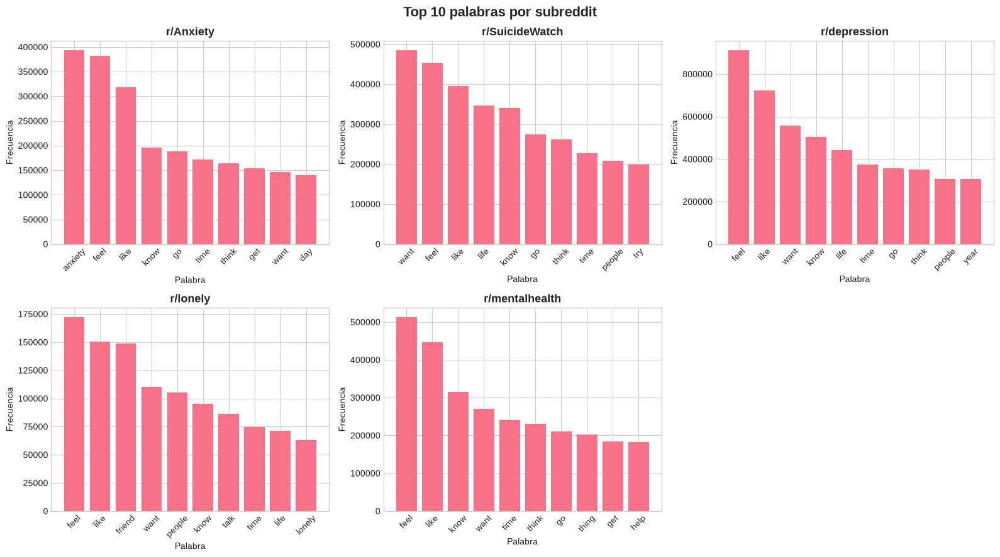

In [9]:
top_words_subreddit = {}
for subreddit in sorted(df_tokens["subreddit"].unique()):
    df_sub = df_tokens[df_tokens["subreddit"] == subreddit]
    freq = get_word_frequencies(df_sub)
    top10 = dict(
        Counter(freq).most_common(10)
    )

    top_words_subreddit[subreddit] = top10

plot_top_words_subreddits(top_words_subreddit, top_n=10)

Para un mayor detalle a nivel temporal, se generan los wordclouds timestrales para cada subreddit 

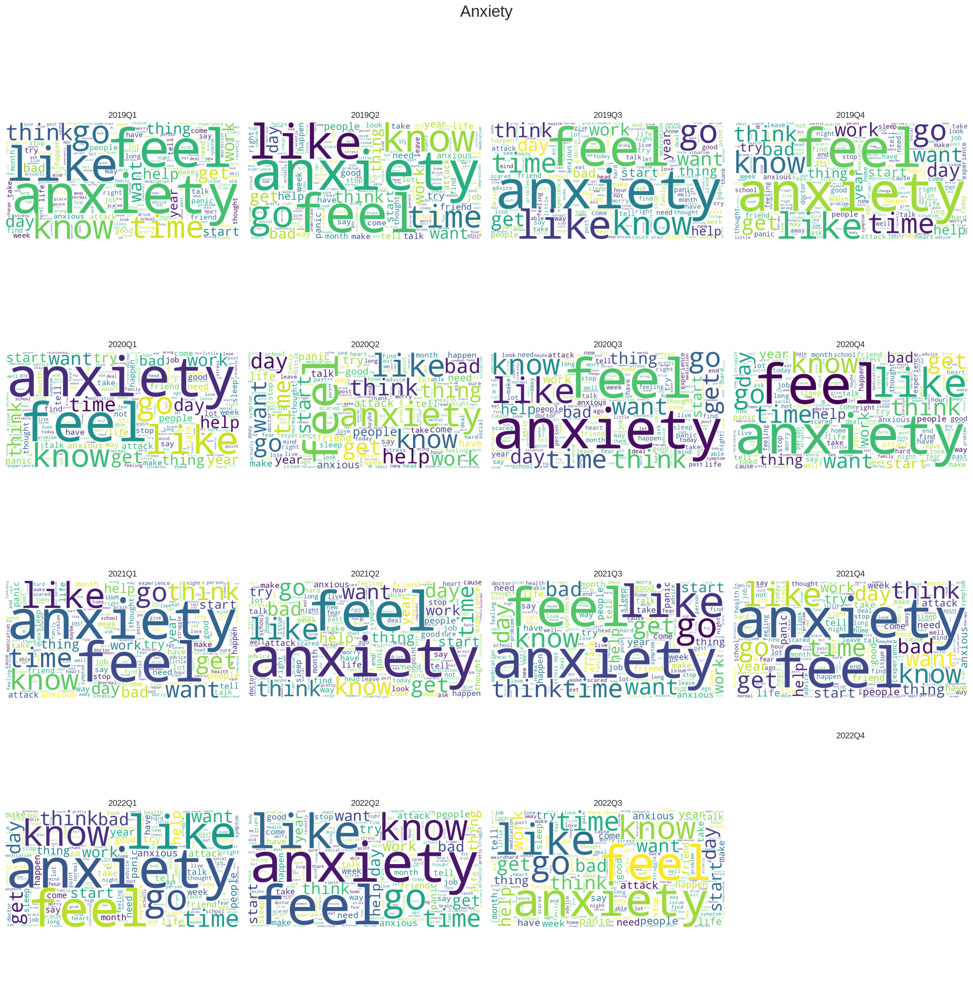

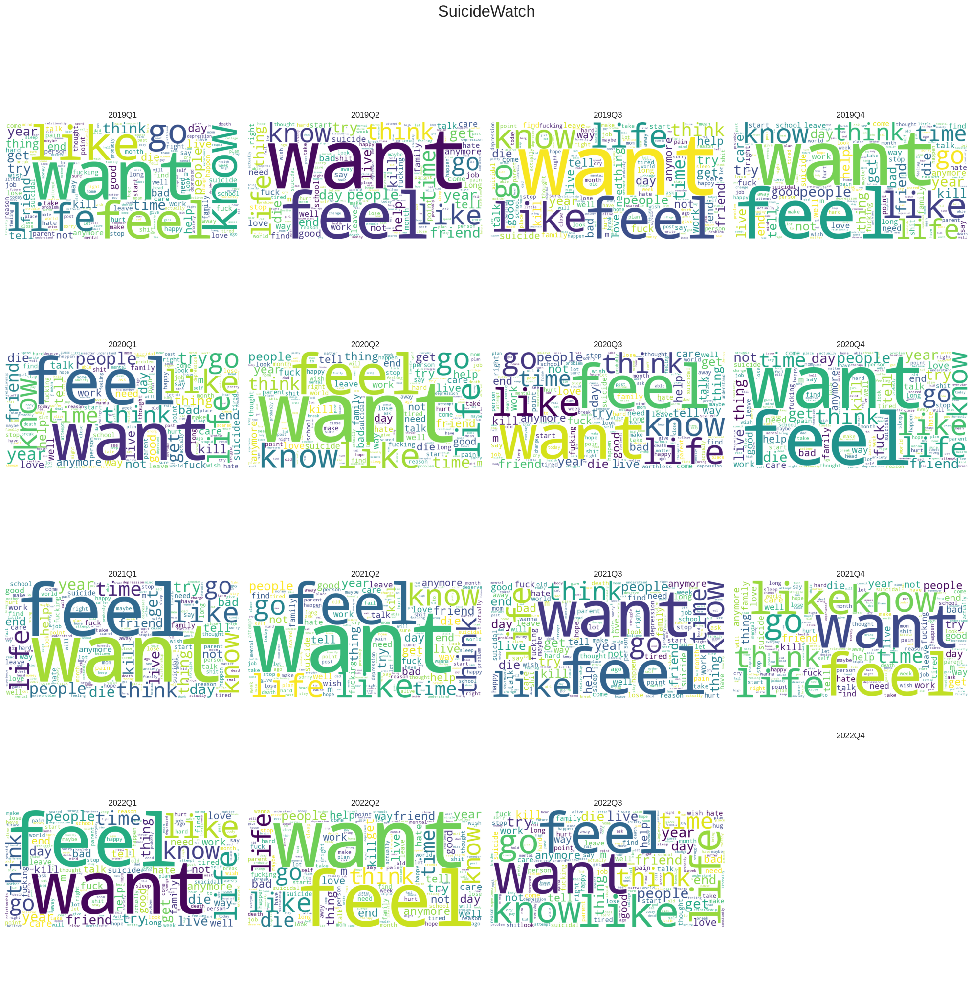

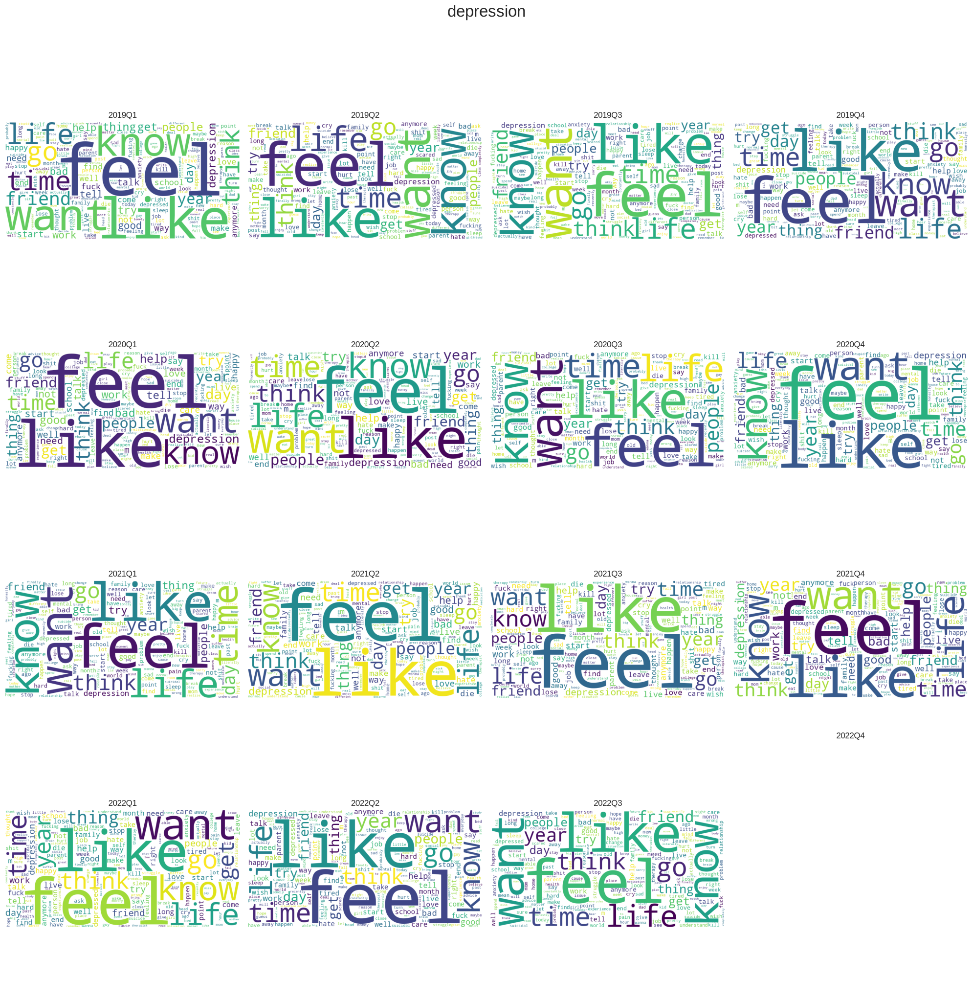

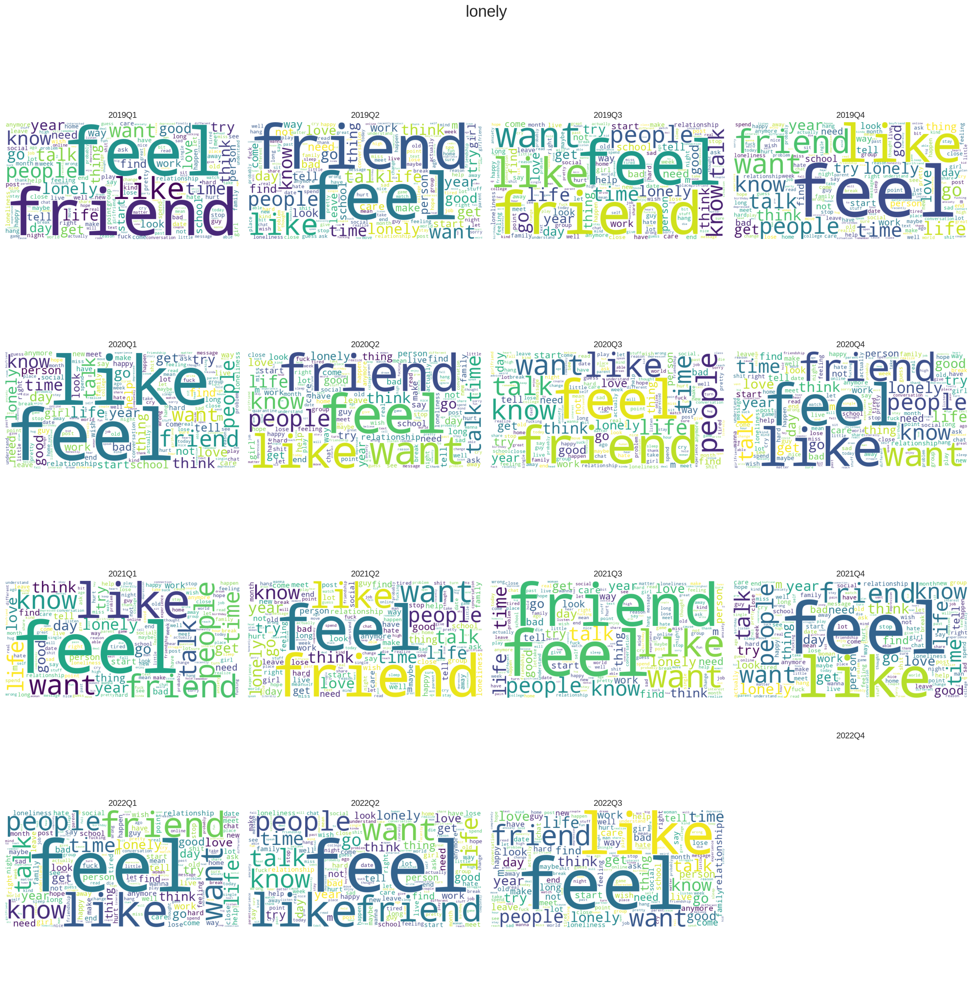

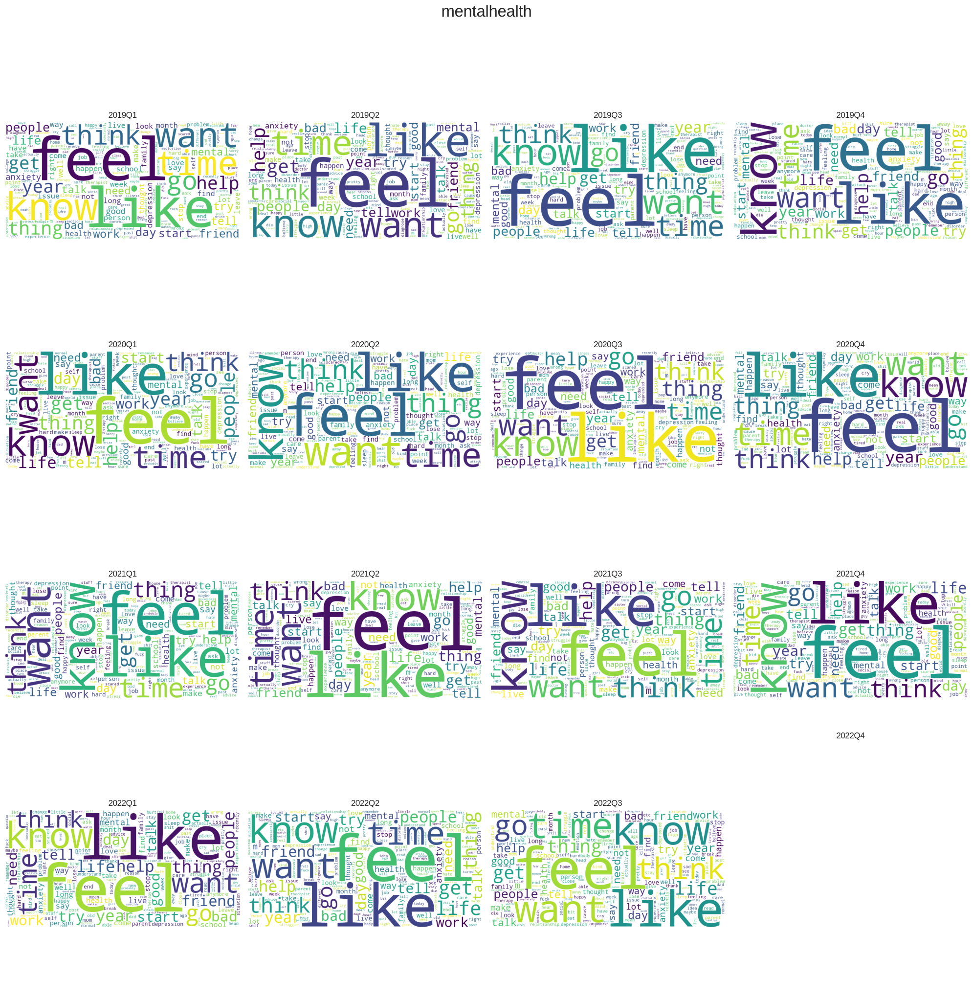

In [10]:
df_tokens["timestamp"] = pd.to_datetime(df_tokens["timestamp"])

subreddits = sorted(df_tokens["subreddit"].unique())

for subreddit in subreddits:
    df_sub = df_tokens[df_tokens["subreddit"] == subreddit].copy()
    df_sub["trimestre"] = df_sub["timestamp"].dt.to_period("Q")

    trimestres = pd.period_range(
        start="2019Q1",
        end="2022Q4",
        freq="Q"
    )

    fig, axes = plt.subplots(4, 4, figsize=(20, 20))
    axes = axes.flatten()

    for ax, trimestre in zip(axes, trimestres):
        df_trim = df_sub[df_sub["trimestre"] == trimestre]
        if len(df_trim) > 0:
            freq = get_word_frequencies(df_trim)
            if len(freq) > 0:
                wc = WordCloud(
                    width=800,
                    height=400,
                    background_color="white"
                ).generate_from_frequencies(freq)
                ax.imshow(wc)

        ax.set_title(str(trimestre), fontsize=12)
        ax.axis("off")

    fig.suptitle(subreddit, fontsize=24, y=1.02)

    plt.tight_layout()
    plt.show()

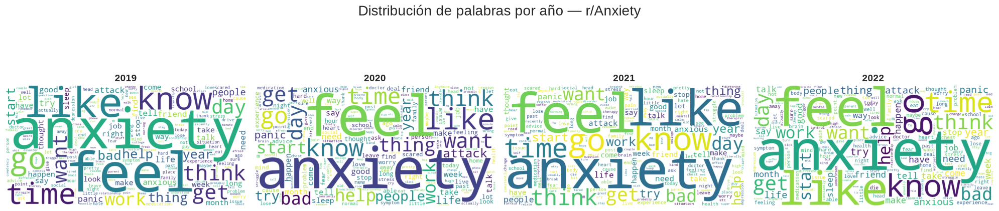

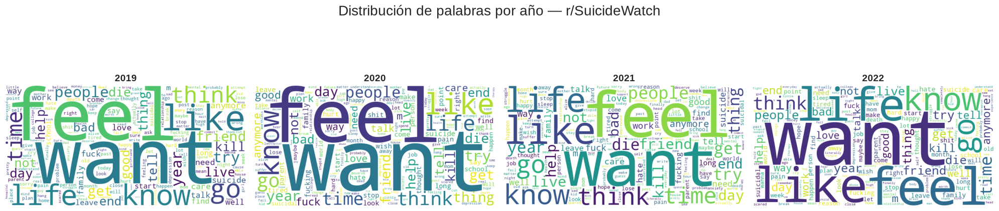

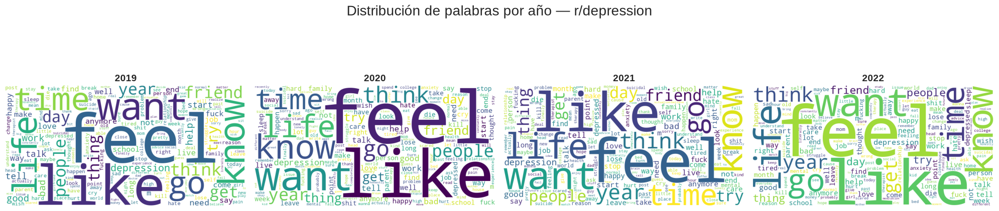

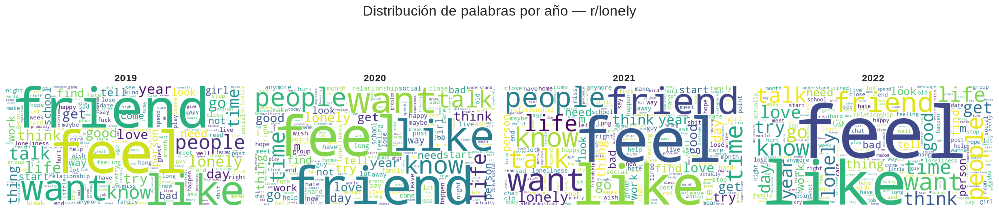

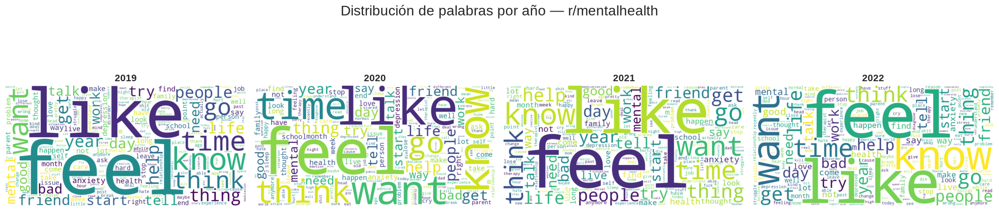

In [11]:
for subreddit in subreddits:    
    df_sub = df_tokens[
        df_tokens["subreddit"] == subreddit
    ].copy()    
    df_sub["año"] = df_sub["timestamp"].dt.year
    años = range(2019, 2023)
    fig, axes = plt.subplots(
        1, 4,
        figsize=(20, 5)
    )
    for ax, año in zip(axes, años):        
        df_año = df_sub[
            df_sub["año"] == año
        ]
        if len(df_año) > 0:            
            freq = get_word_frequencies(df_año)            
            if len(freq) > 0:
                
                wc = WordCloud(
                    width=800,
                    height=400,
                    background_color="white"
                ).generate_from_frequencies(freq)
                
                ax.imshow(wc)

        ax.set_title(
            str(año),
            fontsize=14,
            fontweight="bold"
        )
        
        ax.axis("off")

    fig.suptitle(
        f"Distribución de palabras por año — r/{subreddit}",
        fontsize=20,
        y=1.02
    )

    plt.tight_layout()
    plt.show()

### Bigrams y Skipgrams

Se realiza exploración de los bigrama y skipgramas

In [12]:
def top_ngrams(
    counter,
    top_n=20
):
    '''
    Función para contar los ngramas (ya sean bi o skip)
    '''
    top = pd.DataFrame(
        [
            (
                " ".join(k),
                v
            )
            for k,v
            in counter.most_common(top_n)
        ],
        columns=[
            "ngram",
            "freq"
        ]
    )

    return top

Para visualizar los ngramas, se genera un grafo que permite identificar palabras que están más cerca a otras de acuerdo con la frecuencia con que aparecen juntas

In [13]:
def build_graph(
    counter,
    min_freq=8000
):
    G = nx.Graph()
    for (
        w1,
        w2
    ), count in counter.items():
        if count >= min_freq:
            G.add_edge(
                w1,
                w2,
                weight=count
            )
    return G

def plot_graph(
    G,
    title=""
):
    pos = nx.spring_layout(
        G,
        seed=42,
        k=2.5,
        iterations=300
    )

    # Edges
    edge_traces = []

    for u, v in G.edges():
        x0, y0 = pos[u]
        x1, y1 = pos[v]
        weight = G[u][v].get("weight", 1)
        edge_trace = go.Scatter(
            x=[x0, x1, None],
            y=[y0, y1, None],
            mode="lines",
            line=dict(
                width=weight / 3,
            ),
            hoverinfo="none"
        )

        edge_traces.append(edge_trace)

    # Nodes
    node_x = []
    node_y = []
    node_text = []

    for node in G.nodes():
        x, y = pos[node]

        node_x.append(x)
        node_y.append(y)
        node_text.append(str(node))

    node_trace = go.Scatter(
        x=node_x,
        y=node_y,
        mode="markers+text",
        text=node_text,
        textposition="top center",
        hovertext=node_text,
        hoverinfo="text",
        marker=dict(
            size=12,
            line=dict(width=1)
        )
    )

    fig = go.Figure(
        data=edge_traces + [node_trace]
    )

    fig.update_layout(
        title=title,
        showlegend=False,
        hovermode="closest",
        margin=dict(
            l=20,
            r=20,
            t=50,
            b=20
        ),
        xaxis=dict(
            showgrid=False,
            zeroline=False,
            visible=False
        ),
        yaxis=dict(
            showgrid=False,
            zeroline=False,
            visible=False
        ),
        height=900,
        width=900
    )

    fig.show()

#### Skipgrams

Los **skip-grams** son una extensión de los **n-gramas** que permiten omitir hasta `k` palabras entre los términos.

```python
skipgrams(tokens, n, k)
```

- `tokens`: lista de palabras.
- `n`: tamaño del n-grama.
- `k`: máximo número de palabras que se pueden omitir.

**Ejemplo**

```python
tokens = ["el", "gato", "negro", "duerme"]
```

Con `skipgrams(tokens, 2, 0)`:

```text
(el, gato)
(gato, negro)
(negro, duerme)
```

Con `skipgrams(tokens, 2, 1)`:

```text
(el, gato)
(el, negro)
(gato, negro)
(gato, duerme)
(negro, duerme)
```

Permiten capturar relaciones entre palabras que no necesariamente son consecutivas.

In [14]:
def build_skipgram_counter(df):
    counter = Counter()
    for tokens in df["tokens"]:
        sg = skipgrams(
            tokens,
            2,
            1
        )
        counter.update(sg)
    return counter

In [15]:
G_skipgrams_subreddits = dict()

for sr in subreddits:
    df_sr = df_tokens[df_tokens["subreddit"]==sr]

    skips = build_skipgram_counter(df_sr)

    print(
            f"\nTOP SKIPGRAMAS {sr}"
        )

    print(
            top_ngrams(skips)
        )

    G_skip = build_graph(
            skips
        )

    plot_graph(
            G_skip,
            title=f"{sr} Skipgram Graph"
        )
    G_skipgrams_subreddits[sr] = G_skip


TOP SKIPGRAMAS Anxiety
                 ngram    freq
0            feel like  138010
1         panic attack   61933
2       anxiety attack   21844
3              get bad   17363
4         feel anxious   16908
5         anxiety feel   16681
6          anxiety bad   15998
7                go to   15336
8              like go   14673
9          bad anxiety   13381
10       mental health   13381
11            year ago   13031
12           make feel   12835
13           feel feel   12798
14      social anxiety   12686
15           like feel   12327
16            feel bad   12134
17         anxiety get   12000
18  anxiety depression   11515
19     anxiety anxiety   11054



TOP SKIPGRAMAS SuicideWatch
               ngram    freq
0          feel like  167217
1           want die   58289
2          want want   39975
3              go to   37843
4          want kill   23566
5          want live   22311
6           year old   22214
7            get bad   21834
8   suicidal thought   21506
9          want feel   21458
10          want end   21347
11      want anymore   19672
12          not know   19224
13       good friend   19126
14         feel feel   19057
15          not want   18996
16          end life   18350
17         hate hate   18332
18         know want   18006
19    commit suicide   17867



TOP SKIPGRAMAS depression
            ngram    freq
0       feel like  333451
1       want want   43488
2       feel feel   42512
3        want die   35802
4       know feel   34743
5           go to   34586
6        feel bad   33838
7       want feel   33554
8         get bad   32171
9       like feel   31514
10       year old   31378
11    good friend   31071
12  mental health   30974
13       year ago   28535
14      make feel   28456
15      feel well   27765
16      time feel   27213
17       not know   27206
18      life feel   26947
19    high school   24985



TOP SKIPGRAMAS lonely
            ngram   freq
0       feel like  56572
1     feel lonely  19478
2     good friend  13116
3       want talk   9408
4   friend friend   8012
5     friend feel   7370
6     want friend   7224
7       feel feel   7205
8       want want   7032
9           go to   6903
10      want feel   6848
11    friend talk   6807
12    high school   6579
13    talk people   6514
14       year old   6480
15      know feel   6389
16    like friend   6242
17    people like   6059
18      like feel   5961
19      make feel   5941



TOP SKIPGRAMAS mentalhealth
             ngram    freq
0        feel like  185584
1    mental health   75046
2        feel feel   22149
3        need help   21090
4         year old   20962
5          get bad   19418
6        know feel   19152
7        like feel   18780
8         year ago   18345
9         feel bad   18265
10    panic attack   16796
11      thing like   16289
12       time feel   16181
13           go to   15344
14       make feel   15248
15     good friend   15183
16        not know   15148
17       want want   15136
18  mental illness   15074
19       want feel   15037


#### Bigramas

In [16]:
def build_bigram_counter(df):
    counter = Counter()
    for tokens in df["tokens"]:
        counter.update(
            ngrams(tokens, 2)
        )

    return counter

In [17]:
G_bigrams_subreddits = dict()
for sr in subreddits:
    df_sr = df_tokens[df_tokens["subreddit"]==sr]
    bigrams = build_bigram_counter(df_sr)

    print(
            f"\nTOP BIGRAMAS {sr}"
        )

    print(
            top_ngrams(bigrams)
        )

    G_bigram = build_graph(
            bigrams
        )

    plot_graph(
            G_bigram,
            title=f"{sr} Bigram Graph"
        )
    G_bigrams_subreddits[sr] = G_bigram


TOP BIGRAMAS Anxiety
                 ngram    freq
0            feel like  130493
1         panic attack   60956
2       anxiety attack   16821
3                go to   15274
4              get bad   14329
5        mental health   13156
6             year ago   12381
7         feel anxious   12216
8       social anxiety   12015
9            make feel   11209
10            year old   10555
11             like go    9877
12           month ago    9855
13  anxiety depression    9778
14            feel bad    9296
15         bad anxiety    9217
16      health anxiety    9102
17           feel well    8457
18         anxiety bad    8446
19          start feel    7904



TOP BIGRAMAS SuicideWatch
               ngram    freq
0          feel like  159834
1           want die   52889
2              go to   37649
3           year old   21735
4   suicidal thought   20978
5          want kill   20961
6          want live   18655
7            get bad   17872
8        good friend   17710
9     commit suicide   17700
10          not know   17531
11     mental health   17296
12          want end   17087
13          year ago   16567
14          not want   16024
15          end life   15920
16          feel bad   14115
17          get well   13726
18         need help   13115
19       high school   12878



TOP BIGRAMAS depression
                 ngram    freq
0            feel like  316023
1                go to   34416
2             want die   33184
3        mental health   30595
4             year old   30595
5          good friend   28320
6             feel bad   27387
7             year ago   27351
8              get bad   26589
9             not know   25228
10           make feel   25098
11         high school   24751
12           feel well   21893
13            feel way   20322
14           long time   18944
15           know feel   18062
16           need help   17695
17           want feel   17604
18  depression anxiety   17059
19            get well   16900



TOP BIGRAMAS lonely
           ngram   freq
0      feel like  53052
1    feel lonely  15435
2    good friend  11873
3      want talk   7778
4          go to   6877
5    high school   6543
6       year old   6328
7      make feel   5355
8    talk people   4991
9    want friend   4654
10  close friend   4568
11      year ago   4519
12    spend time   4384
13    new friend   4147
14   friend feel   3942
15      feel bad   3757
16   friend talk   3746
17      feel way   3728
18     long time   3681
19     want feel   3648



TOP BIGRAMAS mentalhealth
                 ngram    freq
0            feel like  175040
1        mental health   74493
2             year old   20502
3            need help   18035
4             year ago   17544
5         panic attack   16504
6              get bad   15968
7                go to   15266
8       mental illness   14754
9             feel bad   14494
10           self harm   14174
11            not know   14073
12         good friend   14037
13           make feel   13461
14         high school   12333
15  depression anxiety   11359
16          thing like   11174
17           long time   10908
18            feel way   10557
19           month ago   10171


#### Métricas

A partir de las redes construidas, se extraen métricas que dan una idea de la forma como se organizan los ngramas en el texto

In [18]:
def network_metrics(G):
    metrics = {}
    metrics["nodes"] = (
        G.number_of_nodes()
    )
    metrics["edges"] = (
        G.number_of_edges()
    )
    metrics["density"] = (
        nx.density(G)
    )
    metrics["transitivity"] = (
        nx.transitivity(G)
    )
    degrees = [
        d
        for _,d
        in G.degree()
    ]
    metrics["avg_degree"] = (
        np.mean(degrees)
    )
    comps = list(
        nx.connected_components(G)
    )
    giant = max(
        comps,
        key=len
    )
    metrics[
        "giant_component_fraction"
    ] = (
        len(giant)
        /
        G.number_of_nodes()
    )

    return metrics

In [19]:
for sr in subreddits:
    G_bigram = G_bigrams_subreddits[sr]
    G_skip = G_skipgrams_subreddits[sr]

    metrics_bigram = (
            network_metrics(
                G_bigram
            )
        )

    metrics_skip = (
            network_metrics(
                G_skip
            )
        )

    metrics_df = pd.DataFrame(
            [
                metrics_bigram,
                metrics_skip
            ],
            index=[
                "bigram",
                "skipgram"
            ]
        )
    
    print("-"*20,sr,"-"*20)
    display(metrics_df)

-------------------- Anxiety --------------------


,nodes,edges,density,transitivity,avg_degree,giant_component_fraction
bigram,20,18,0.094737,0.000000,1.8000,0.8
skipgram,32,43,0.086694,0.150685,2.6875,1.0


-------------------- SuicideWatch --------------------


,nodes,edges,density,transitivity,avg_degree,giant_component_fraction
bigram,45,44,0.044444,0.179487,1.955556,0.511111
skipgram,59,95,0.055523,0.259179,3.220339,0.728814


-------------------- depression --------------------


,nodes,edges,density,transitivity,avg_degree,giant_component_fraction
bigram,70,83,0.034369,0.138817,2.371429,0.614286
skipgram,91,200,0.048840,0.290625,4.395604,0.791209


-------------------- lonely --------------------


,nodes,edges,density,transitivity,avg_degree,giant_component_fraction
bigram,5,3,0.300000,0,1.200000,0.600000
skipgram,7,5,0.238095,0,1.428571,0.428571


-------------------- mentalhealth --------------------


,nodes,edges,density,transitivity,avg_degree,giant_component_fraction
bigram,38,27,0.038407,0.000000,1.421053,0.342105
skipgram,46,56,0.054106,0.217949,2.434783,0.586957


In [20]:
def centralities(G):
    deg = nx.degree_centrality(G)
    bet = nx.betweenness_centrality(
        G
    )
    eig = nx.eigenvector_centrality(
        G,
        max_iter=1000
    )
    deg_df = (
        pd.DataFrame(
            deg.items(),
            columns=[
                "word",
                "degree"
            ]
        )
        .sort_values(
            "degree",
            ascending=False
        )
    )

    bet_df = (
        pd.DataFrame(
            bet.items(),
            columns=[
                "word",
                "betweenness"
            ]
        )
        .sort_values(
            "betweenness",
            ascending=False
        )
    )

    eig_df = (
        pd.DataFrame(
            eig.items(),
            columns=[
                "word",
                "eigenvector"
            ]
        )
        .sort_values(
            "eigenvector",
            ascending=False
        )
    )

    return (
        deg_df,
        bet_df,
        eig_df
    )

In [21]:
for sr in subreddits:
    print("-"*20,sr,"-"*20)
    G_bigram = G_bigrams_subreddits[sr]
    (
        degree_df_bigram,
        betweenness_df_bigram,
        eigen_df_bigram
    ) = centralities(
        G_bigram
    ) 

    print("BIGRAM")
    print("TOP DEGREE")
    display(degree_df_bigram)
    print("TOP BETWEENNESS")
    display(betweenness_df_bigram)
    print("TOP EIGENVECTOR")
    display(eigen_df_bigram)

    G_skip = G_skipgrams_subreddits[sr]
    (
        degree_df_skipgram,
        betweenness_df_skipgram,
        eigen_df_skipgram
    ) = centralities(
        G_skip
    ) 

    print("SKIPGRAM")
    print("TOP DEGREE")
    display(degree_df_skipgram)
    print("TOP BETWEENNESS")
    display(betweenness_df_skipgram)
    print("TOP EIGENVECTOR")
    display(eigen_df_skipgram)



-------------------- Anxiety --------------------
BIGRAM
TOP DEGREE


,word,degree
11,anxiety,0.263158
6,feel,0.263158
9,bad,0.157895
1,attack,0.105263
7,like,0.105263
5,ago,0.105263
2,go,0.105263
4,year,0.105263
15,health,0.105263
0,panic,0.052632


TOP BETWEENNESS


,word,betweenness
11,anxiety,0.391813
6,feel,0.385965
9,bad,0.368421
7,like,0.152047
15,health,0.081871
1,attack,0.081871
2,go,0.081871
4,year,0.011696
5,ago,0.011696
0,panic,0.000000


TOP EIGENVECTOR


...

,word,degree
11,feel,0.422222
3,like,0.222222
6,know,0.200000
4,want,0.177778
5,help,0.088889
18,time,0.088889
35,go,0.088889
19,year,0.066667
14,day,0.066667
34,people,0.066667


TOP BETWEENNESS


,word,betweenness
11,feel,0.251010
18,time,0.049495
3,like,0.043603
4,want,0.036700
22,bad,0.025253
5,help,0.025253
35,go,0.025253
43,good,0.025253
6,know,0.020202
19,year,0.005051


TOP EIGENVECTOR


,word,eigenvector
11,feel,5.499833e-01
3,like,3.959757e-01
6,know,3.875353e-01
4,want,3.264050e-01
35,go,2.195503e-01
34,people,2.139012e-01
5,help,2.080954e-01
18,time,1.599711e-01
40,thing,1.517386e-01
8,not,1.145194e-01


##### Información Mutua Puntual

##### Medida de Diversidad Léxica Textual

### Análisis temporal

Para el análisis temporal del texto y las variaciones correspondientes, se tienen en cuenta medidas de diversidad léxica y asociación entre ngramas. Inicialmente se construye la función para agregar por periodo temporal

In [22]:
def assign_period(df, date_col="timestamp"):
    """Agrega la columna 'period' en formato 'YYYYQn' a partir de una columna temporal."""
    df = df.copy()
    dt = pd.to_datetime(df[date_col], errors="coerce")
    df["_dt"] = dt
    year = dt.dt.year.astype("Int64").astype(str)
    q = dt.dt.quarter.astype("Int64").astype(str)
    df["period"] = year + "Q" + q
    df.loc[dt.isna(), "period"] = np.nan
    return df

Conteo de ngramas

In [23]:
def compute_group_counters(df, group_cols, tokens_col="tokens",
                            window_size=2, skip_k=1,
                            compute_skipgrams=True):
    """
    Recorre el DataFrame UNA sola vez por cada combinación de group_cols
    y calcula, en la misma pasada, word_freq, bigram_freq y skipgram_freq.
    """
    results = {}
    for key, sub in df.groupby(list(group_cols), sort=False):
        word_freq = Counter()
        bigram_freq = Counter()
        skip_freq = Counter() if compute_skipgrams else None
        n_tokens = 0
        for toks in sub[tokens_col]:
            word_freq.update(toks)
            n_tokens += len(toks)
            bigram_freq.update(zip(toks, toks[1:]))
            if compute_skipgrams:
                skip_freq.update(skipgrams(toks, window_size, skip_k))
        results[key] = {
            "word_freq": word_freq,
            "bigram_freq": bigram_freq,
            "skipgram_freq": skip_freq,
            "n_tokens": n_tokens,
            "n_comments": len(sub),
        }
    return results

Se realiza cálculo de NPMI entre pares para identificar aquellas palabras que aparecen juntas más veces de lo esperado

In [24]:
def calculate_npmi(word_freq, pair_freq, n_tokens, n_pairs,
                    min_word_freq=30, min_pair_freq=10):
    """
    NPMI = PMI(x,y) / -log(p(x,y))  ∈ [-1, 1]
    """
    rows = []
    for (w1, w2), freq in pair_freq.items():
        if freq < min_pair_freq:
            continue
        f1 = word_freq.get(w1, 0)
        f2 = word_freq.get(w2, 0)
        if f1 < min_word_freq or f2 < min_word_freq:
            continue
        p_xy = freq / n_pairs
        p_x = f1 / n_tokens
        p_y = f2 / n_tokens
        if p_xy <= 0 or p_x <= 0 or p_y <= 0:
            continue
        pmi = math.log(p_xy / (p_x * p_y))
        denom = -math.log(p_xy)
        npmi = pmi / denom if denom != 0 else 0.0
        rows.append((w1, w2, freq, pmi, npmi))
    cols = ["word_1", "word_2", "frequency", "pmi", "npmi"]
    if not rows:
        return pd.DataFrame(columns=cols)
    out = pd.DataFrame(rows, columns=cols)
    return out.sort_values("npmi", ascending=False).reset_index(drop=True)

def compute_npmi_for_groups(group_counters, group_cols, pair_type="bigram_freq",
                             min_word_freq=30, min_pair_freq=10):
    """
    Aplica calculate_npmi() a cada grupo y devuelve un único DataFrame largo
    con columnas de grupo + word_1, word_2, frequency, pmi, npmi.
    """
    all_dfs = []
    for key, data in group_counters.items():
        pair_freq = data[pair_type]
        if not pair_freq:
            continue
        n_pairs = sum(pair_freq.values())
        n_tokens = sum(data["word_freq"].values())
        if n_pairs == 0 or n_tokens == 0:
            continue
        df_npmi = calculate_npmi(data["word_freq"], pair_freq, n_tokens, n_pairs,
                                  min_word_freq=min_word_freq, min_pair_freq=min_pair_freq)
        if df_npmi.empty:
            continue
        key_tuple = key if isinstance(key, tuple) else (key,)
        for col, val in zip(group_cols, key_tuple):
            df_npmi[col] = val
        df_npmi["ngram_type"] = "bigram" if pair_type == "bigram_freq" else "skipgram"
        all_dfs.append(df_npmi)
    if not all_dfs:
        return pd.DataFrame(columns=["word_1", "word_2", "frequency", "pmi", "npmi"]
                             + list(group_cols) + ["ngram_type"])
    return pd.concat(all_dfs, ignore_index=True)

Calcula la MTLD para identificar diversidad léxica textual y comparar subreddits con vocabularios más variados

In [25]:
def _mtld_pass(tokens, threshold=0.72):
    """Una pasada (forward o backward) del algoritmo MTLD estándar."""
    if len(tokens) < 2:
        return 0.0
    factors = 0
    types = set()
    token_count = 0
    for tok in tokens:
        types.add(tok)
        token_count += 1
        ttr = len(types) / token_count
        if ttr <= threshold:
            factors += 1
            types = set()
            token_count = 0
    if token_count > 0:
        ttr = len(types) / token_count
        remainder = (1 - ttr) / (1 - threshold) if threshold != 1 else 0
        factors += remainder
    return len(tokens) / factors if factors > 0 else 0.0


def calculate_mtld(tokens, threshold=0.72, max_tokens=200000, seed=42):
    """MTLD = promedio de la pasada forward y backward sobre la secuencia de tokens."""
    tokens = list(tokens)
    if len(tokens) > max_tokens:
        rng = np.random.default_rng(seed)
        start = rng.integers(0, len(tokens) - max_tokens)
        tokens = tokens[start:start + max_tokens]
    if len(tokens) < 10:
        return np.nan
    forward = _mtld_pass(tokens, threshold)
    backward = _mtld_pass(list(reversed(tokens)), threshold)
    return float(np.mean([forward, backward]))


def calculate_lexical_diversity(df, group_cols, tokens_col="tokens", threshold=0.72):
    """Calcula MTLD por cada combinación de group_cols (p.ej. ["subreddit","period"])."""
    rows = []
    for key, sub in df.groupby(list(group_cols), sort=False):
        token_stream = list(itertools.chain.from_iterable(sub[tokens_col]))
        mtld_val = calculate_mtld(token_stream, threshold=threshold)
        key_tuple = key if isinstance(key, tuple) else (key,)
        row = dict(zip(group_cols, key_tuple))
        row["n_tokens"] = len(token_stream)
        row["n_comments"] = len(sub)
        row["MTLD"] = mtld_val
        rows.append(row)
    return pd.DataFrame(rows)


Se consolidan los resultados en df

In [28]:
def _basic_stats_by_group(group_counters, group_cols):
    rows = []
    for key, data in group_counters.items():
        key_tuple = key if isinstance(key, tuple) else (key,)
        row = dict(zip(group_cols, key_tuple))
        n_words = data["n_tokens"]
        n_comments = data["n_comments"]
        row["n_comments"] = n_comments
        row["avg_words"] = n_words / n_comments if n_comments else np.nan
        row["vocab_size"] = len(data["word_freq"])
        rows.append(row)
    return pd.DataFrame(rows)


def run_eda_pipeline(df, group_cols, tokens_col="tokens",
                      min_word_freq=30, min_pair_freq=10,
                      pair_type="bigram_freq"):
    """
    Corre stats básicas + MTLD + resumen de NPMI (mean/max) para el nivel de
    agregación dado por group_cols. Se usa para construir Tabla 1 (a nivel subreddit).
    """
    group_counters = compute_group_counters(
        df, group_cols, tokens_col=tokens_col,
        compute_skipgrams=(pair_type == "skipgram_freq")
    )

    df_basic = _basic_stats_by_group(group_counters, group_cols)

    df_mtld = calculate_lexical_diversity(df, group_cols, tokens_col=tokens_col)
    df_mtld = df_mtld[group_cols + ["MTLD"]]

    npmi_all = compute_npmi_for_groups(
        group_counters, group_cols, pair_type=pair_type,
        min_word_freq=min_word_freq, min_pair_freq=min_pair_freq
    )

    npmi_summary_rows = []
    if not npmi_all.empty:
        for key, sub_npmi in npmi_all.groupby(group_cols, sort=False):
            key_tuple = key if isinstance(key, tuple) else (key,)
            base = dict(zip(group_cols, key_tuple))
            npmi_summary_rows.append({
                **base,
                "npmi_mean": sub_npmi["npmi"].mean(),
                "npmi_max": sub_npmi["npmi"].max(),
                "n_pairs_valid": len(sub_npmi),
            })

    df_npmi_summary = pd.DataFrame(npmi_summary_rows) if npmi_summary_rows else \
        pd.DataFrame(columns=group_cols + ["npmi_mean", "npmi_max", "n_pairs_valid"])

    master = df_basic.merge(df_mtld, on=group_cols, how="left")
    master = master.merge(df_npmi_summary, on=group_cols, how="left")

    return {"master": master}


def build_eda_summary(df, tokens_col="tokens", top_n=10,
                       min_word_freq=30, min_pair_freq=10,
                       pair_type="bigram_freq"):
    """
    Genera únicamente lo necesario para:
      table_subreddit : resumen general por subreddit (n_comments, avg_words,
                          vocab_size, MTLD, npmi_mean/max)
      table_npmi_top   : top-N asociaciones NPMI por subreddit x periodo
      mtld_temporal     : MTLD por subreddit x periodo (insumo de las 2 gráficas)
    """
    res_sr = run_eda_pipeline(df, ["subreddit"], tokens_col,
                               min_word_freq, min_pair_freq, pair_type)

    group_counters_srp = compute_group_counters(
        df, ["subreddit", "period"], tokens_col=tokens_col,
        compute_skipgrams=(pair_type == "skipgram_freq")
    )
    npmi_srp = compute_npmi_for_groups(
        group_counters_srp, ["subreddit", "period"], pair_type=pair_type,
        min_word_freq=min_word_freq, min_pair_freq=min_pair_freq
    )

    if not npmi_srp.empty:
        table3 = (npmi_srp
                  .sort_values(["subreddit", "period", "npmi"], ascending=[True, True, False])
                  .groupby(["subreddit", "period"], sort=False)
                  .head(top_n)
                  .reset_index(drop=True))
        table3 = table3[["subreddit", "period", "word_1", "word_2", "frequency", "pmi", "npmi", "ngram_type"]]
    else:
        table3 = pd.DataFrame(columns=["subreddit", "period", "word_1", "word_2",
                                        "frequency", "pmi", "npmi", "ngram_type"])

    mtld_temporal = calculate_lexical_diversity(df, ["subreddit", "period"], tokens_col=tokens_col)

    return {
        "table_subreddit": res_sr["master"],
        "table_npmi_top": table3,
        "mtld_temporal": mtld_temporal,
    }

Se visualizan los resultados en gráficas

In [33]:
def plot_mtld_evolution(mtld_temporal, figsize=(12, 10)):
    """
    Evolución temporal de la diversidad léxica (MTLD)
    por subreddit y trimestre mediante pequeños múltiplos.
    """
    df = mtld_temporal.copy()
    period_order = sorted(df["period"].unique())
    subreddits = sorted(df["subreddit"].unique())
    y_min = df["MTLD"].min() - 5
    y_max = df["MTLD"].max() + 5

    fig, axes = plt.subplots(
        nrows=len(subreddits),
        ncols=1,
        figsize=figsize,
        sharex=True,
        sharey=True
    )

    if len(subreddits) == 1:
        axes = [axes]

    for ax, subreddit in zip(axes, subreddits):

        df_sub = (
            df[df["subreddit"] == subreddit]
            .set_index("period")
            .reindex(period_order)
            .reset_index()
        )

        ax.plot(
            df_sub["period"].astype(str),
            df_sub["MTLD"],
            marker="o",
            linewidth=2,
            markersize=5
        )

        ax.set_title(
            subreddit,
            loc="left",
            fontsize=11,
            fontweight="bold"
        )

        ax.set_ylim(y_min, y_max)
        ax.grid(axis="y", alpha=0.3)

        # Línea de media del subreddit
        mean_mtld = df_sub["MTLD"].mean()

        ax.axhline(
            mean_mtld,
            linestyle="--",
            linewidth=1,
            alpha=0.6
        )

        ax.text(
            1.01,
            mean_mtld,
            f"Media: {mean_mtld:.1f}",
            transform=ax.get_yaxis_transform(),
            va="center",
            fontsize=9
        )

    # Eje X solamente en el último panel
    axes[-1].set_xlabel("Periodo")

    # Reducir cantidad de etiquetas
    tick_positions = range(0, len(period_order), 2)

    axes[-1].set_xticks(tick_positions)
    axes[-1].set_xticklabels(
        [str(period_order[i]) for i in tick_positions],
        rotation=30,
        ha="right"
    )

    fig.suptitle(
        "Evolución de la diversidad léxica (MTLD) por subreddit",
        fontsize=15,
        fontweight="bold",
        y=0.995
    )

    fig.text(
        0.01,
        0.5,
        "MTLD",
        va="center",
        rotation="vertical"
    )

    fig.tight_layout()

    return fig


def plot_diversity_comparison(mtld_temporal, figsize=(8, 5)):
    """Comparación de diversidad léxica (MTLD) entre subreddits (distribución across periodos)."""
    fig, ax = plt.subplots(figsize=figsize)
    sns.boxplot(data=mtld_temporal, x="subreddit", y="MTLD", ax=ax)
    ax.set_title("Comparación de diversidad léxica (MTLD) entre subreddits")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    return fig

def plot_npmi_top_pairs(
    table2,
    top_n=10,
    min_frequency=30,
    figsize=(12, 14)
):
    """
    Visualiza los pares de palabras con mayor NPMI promedio
    por subreddit, agregados a través de los periodos.
    """

    df = table2.copy()
    df["pair"] = (
        df["word_1"].astype(str)
        + " "
        + df["word_2"].astype(str)
    )
    df_agg = (
        df
        .groupby(["subreddit", "pair"], as_index=False)
        .agg(
            npmi_mean=("npmi", "mean"),
            frequency_total=("frequency", "sum"),
            periods=("period", "nunique")
        )
    )
    df_agg = df_agg[
        df_agg["frequency_total"] >= min_frequency
    ].copy()

    df_top = (
        df_agg
        .sort_values(
            ["subreddit", "npmi_mean"],
            ascending=[True, False]
        )
        .groupby("subreddit", group_keys=False)
        .head(top_n)
        .copy()
    )

    subreddits = sorted(
        df_top["subreddit"].unique()
    )

    fig, axes = plt.subplots(
        nrows=len(subreddits),
        ncols=1,
        figsize=figsize
    )

    if len(subreddits) == 1:
        axes = [axes]

    for ax, subreddit in zip(axes, subreddits):

        df_sub = (
            df_top[
                df_top["subreddit"] == subreddit
            ]
            .sort_values(
                "npmi_mean",
                ascending=True
            )
        )

        sns.barplot(
            data=df_sub,
            x="npmi_mean",
            y="pair",
            ax=ax
        )

        # Título
        ax.set_title(
            subreddit,
            loc="left",
            fontsize=12,
            fontweight="bold"
        )

        # Etiquetas
        ax.set_xlabel("NPMI promedio")
        ax.set_ylabel("Par de palabras")

        # Grid
        ax.grid(
            axis="x",
            alpha=0.3
        )

        # Limitar eje X
        ax.set_xlim(
            0,
            min(1, df_sub["npmi_mean"].max() + 0.08)
        )

        for container in ax.containers:
            labels = [
                f"{bar.get_width():.2f}"
                for bar in container
            ]

            ax.bar_label(
                container,
                labels=labels,
                padding=3,
                fontsize=9
            )

    fig.suptitle(
        "Principales asociaciones léxicas por subreddit",
        fontsize=16,
        fontweight="bold",
        y=0.995
    )

    # Subtítulo metodológico
    fig.text(
        0.5,
        0.01,
        (
            f"Top {top_n} pares según NPMI promedio entre periodos | "
            f"Frecuencia acumulada mínima: {min_frequency}"
        ),
        ha="center",
        fontsize=10
    )

    # Ajustar espacios
    fig.tight_layout(
        rect=[0, 0.03, 1, 0.98]
    )

    return fig

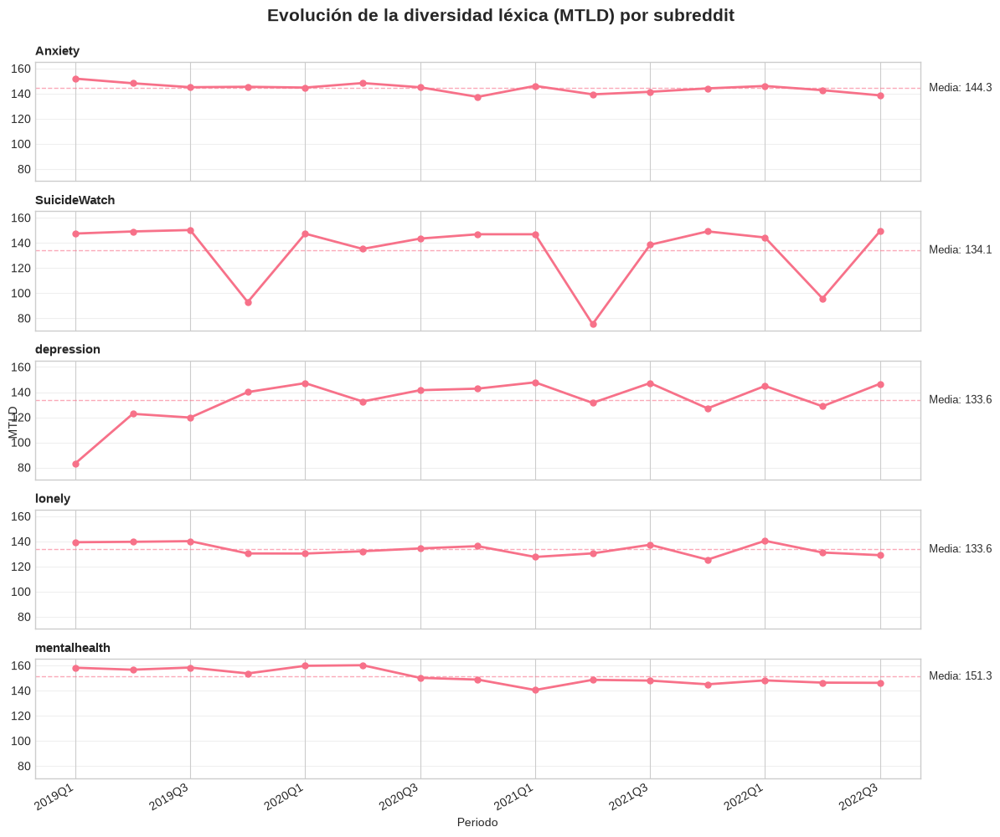

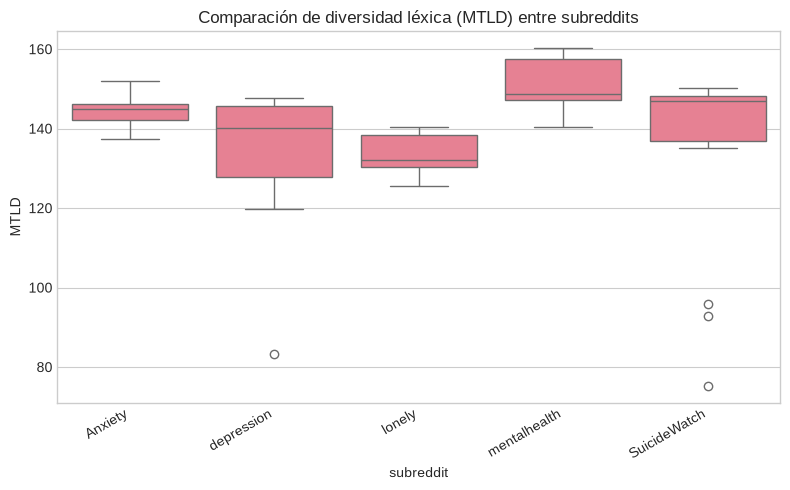

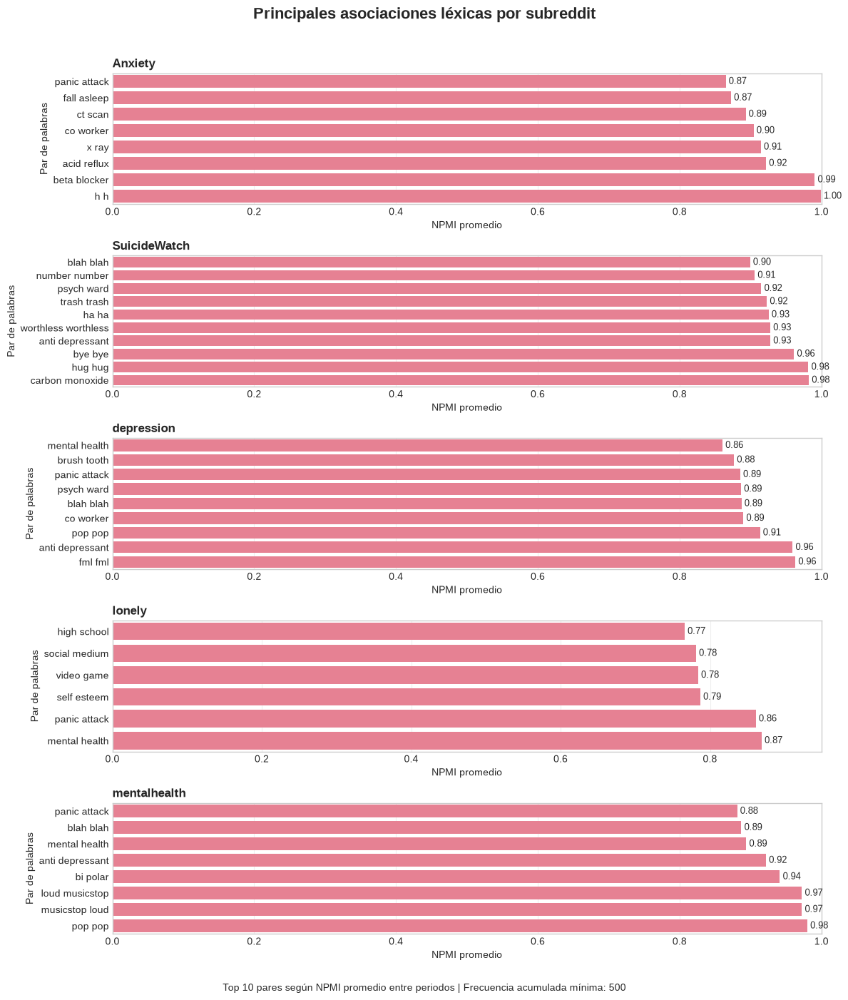

In [36]:
df_tokens = assign_period(df_tokens, date_col="timestamp")

tables = build_eda_summary(
    df_tokens,
    tokens_col="tokens",
    top_n=10,
    min_word_freq=30,
    min_pair_freq=10,
    pair_type="bigram_freq",      
)

table1 = tables["table_subreddit"]
table2 = tables["table_npmi_top"]

fig = plot_mtld_evolution(tables["mtld_temporal"])
plt.show()
plt.close(fig)

fig = plot_diversity_comparison(tables["mtld_temporal"])
plt.show()
plt.close(fig)

fig = plot_npmi_top_pairs(
    table2,
    top_n=10,
    min_frequency=500
)
plt.show()
plt.close(fig)

# Grafo

In [2]:
df = pd.read_parquet("../Datasets/RMHD_limpio_completo.parquet")
df

,author,score,subreddit,timestamp,year,month,text,text_clean
0,tcarrollsmit,21,Anxiety,2019-08-31 23:59:28,2019,aug,IBS & anxiety Anyone here have IBS due to anxi...,ibs anxiety ib anxiety find way reduce anxiety...
1,Jane_Meki_Jane,1,Anxiety,2019-08-31 23:40:11,2019,aug,Was gonna get what I thought I needed but turn...,go to think need turn read wrong browse store ...
2,G-Random20,1,Anxiety,2019-08-31 23:36:47,2019,aug,"If my anxiety could talk... Anxiety: -Hey, you...",anxiety talk anxiety worry anxiety worry hope...
3,mimiforu,1,Anxiety,2019-08-31 23:32:37,2019,aug,I suffer from panic disorder and weekends seem...,suffer panic disorder weekend bring bit peace ...
4,G-Random20,1,Anxiety,2019-08-31 23:26:22,2019,aug,"If my anxiety could talk... Anxiety: -Hey, you...",anxiety talk anxiety worry anxiety worry hope...
...,...,...,...,...,...,...,...,...
1817562,username1627,1,SuicideWatch,2022-05-01 00:17:47,2022,may,"Useless Rant Whenever I see comments such as ""...",useless rant comment well care miss like feel ...
1817563,verycoolusername231,1,SuicideWatch,2022-05-01 00:13:08,2022,may,There is nothing. What even is the purpose in ...,purpose life life accident chemical interracti...
1817564,mogana_sunset,1,SuicideWatch,2022-05-01 00:10:49,2022,may,"Why am I still here, just to suffer?",suffer
1817565,uaipqwhy,1,SuicideWatch,2022-05-01 00:06:44,2022,may,countdown 2? Idk if I gonna or not do it. \nBu...,countdown go to hope


## Embeddings

Dada la complejidad del lenguaje en Reddit (sarcasmo, polisemias, abreviaciones, extranjerismos), los embeddings requieren enfoques más complejos que permitan captar el contexto y el contenido. Por tal motivo, se utiliza BAAI, un modelo entrenado y enfocado en inglés que, publicado en 2024, estableció un estado del arte, garantizando calidad ante comentarios variados.

https://arxiv.org/abs/2402.03216

In [ ]:
def compute_embeddings(
    texts,
    model_name='BAAI/bge-small-en-v1.5',
    cache_path=None,
    batch_size=64,
    chunk_size=2000,          # cuántos textos procesar antes de guardar
    local_model_dir=None,
    force_recompute=False,
):
    cache_path = Path(cache_path) if cache_path else None
    tmp_dir = cache_path.with_suffix('') if cache_path else Path('embeddings_tmp')
    tmp_dir = Path(str(tmp_dir) + '_chunks')

    # 1. Si ya existe el archivo final, no recalcules nada
    if cache_path and cache_path.exists() and not force_recompute:
        print(f"✅ Cargando embeddings desde caché: {cache_path}")
        return np.load(cache_path)

    # 2. Usar todos los núcleos disponibles
    n_threads = os.cpu_count()
    torch.set_num_threads(n_threads)
    print(f"🧵 Usando {n_threads} hilos de CPU")

    # 3. Modo offline (usa el modelo ya descargado, sin tocar internet)
    os.environ.setdefault("HF_HUB_OFFLINE", "1")
    os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")

    print(f"🔄 Calculando embeddings con {model_name}...")
    model_path = local_model_dir if local_model_dir else model_name
    model = SentenceTransformer(model_path, device="cpu")
    model.max_seq_length = 512

    # 4. Preparar carpeta de bloques (checkpoints)
    tmp_dir.mkdir(parents=True, exist_ok=True)
    n_texts = len(texts)
    n_chunks = (n_texts + chunk_size - 1) // chunk_size

    if force_recompute:
        # Borra bloques viejos si se pide recalcular desde cero
        for f in tmp_dir.glob("chunk_*.npy"):
            f.unlink()

    # 5. Procesar bloque por bloque, saltando los que ya existen
    for i in range(n_chunks):
        chunk_file = tmp_dir / f"chunk_{i:05d}.npy"
        if chunk_file.exists():
            print(f"⏭️  Bloque {i+1}/{n_chunks} ya existe, saltando...")
            continue

        start = i * chunk_size
        end = min(start + chunk_size, n_texts)
        chunk_texts = texts[start:end]

        print(f"🔹 Bloque {i+1}/{n_chunks} (textos {start}-{end})...")
        chunk_embeddings = model.encode(
            chunk_texts,
            batch_size=batch_size,
            convert_to_numpy=True,
            show_progress_bar=True,
            normalize_embeddings=True,
        )

        # Guardado atómico: escribe a un .tmp y luego renombra,
        # así un corte de luz a mitad de escritura no deja el bloque corrupto
        tmp_file = chunk_file.with_suffix('.tmp.npy')
        np.save(tmp_file, chunk_embeddings)
        os.replace(tmp_file, chunk_file)
        print(f"💾 Bloque {i+1}/{n_chunks} guardado en {chunk_file}")

    # 6. Unir todos los bloques en el array final
    print("🔗 Uniendo bloques...")
    all_chunks = [np.load(tmp_dir / f"chunk_{i:05d}.npy") for i in range(n_chunks)]
    embeddings = np.concatenate(all_chunks, axis=0)

    # 7. Guardar el resultado final y limpiar bloques temporales
    if cache_path:
        np.save(cache_path, embeddings)
        print(f"💾 Embeddings finales guardados en {cache_path}")
        for f in tmp_dir.glob("chunk_*.npy"):
            f.unlink()
        tmp_dir.rmdir()

    return embeddings


embeddings = compute_embeddings(
    df['text_clean'].tolist(),
#    model_name='BAAI/bge-small-en-v1.5',
    model_name = "all-MiniLM-L6-v2",
    cache_path=r'..\Datasets\Embeddings\embeddings_allmini.npy',
    chunk_size=10000,   # ajusta según cuántos textos tengas (ver nota abajo)
)

df['embedding_idx'] = range(len(df))

print(f"\n Embeddings shape: {embeddings.shape}")
print(f"   Dimensión por post: {embeddings.shape[1]}")
print(f"   Memoria aproximada: {embeddings.nbytes / 1e6:.1f} MB")

✅ Cargando embeddings desde caché: embeddings_bge_small.npy

 Embeddings shape: (1817567, 384)
   Dimensión por post: 384
   Memoria aproximada: 2791.8 MB


Se hace uso de Embedkit para analizar las métricas del embedding creado, permitiendo reducir dimensionalidad, mejorar su calidad y garantizar representaciones precisas.

Dado que la librería realiza el análisis a partir de la selección el hiperparámetro k, se prueban con varios valores

In [12]:
for i in [10,20,30,40,50]:
    print("===================",i,"===================")
    report = EmbedKitAnalyzer(k=i).fit(embeddings)  
    report.print_summary()

=================== 10 ===================

  EmbedKit Analysis Report  (1817567 samples × 384 dims)

[Intrinsic Dimension]
  consensus ID     : 28.12  (±17.54)
  TwoNN         : 29.00
  MLE           : 19.69
  lPCA          : 65.00
  MOM           : 27.23

[Hubness]
  k-skewness       : 3.552
  Robin Hood index : -0.544
  hub ratio        : 0.121
  antihub ratio    : 0.059
  hub contamination: 0.721

[Geometry]
  participation_ratio : 63.93
  isotropy_score      : 0.372
  relative_contrast   : 1.313
  neighbor_consistency: 0.985
  uniformity          : -2.5649

[Kernel]
  sigma            : 1.1809
  effective_rank   : 4.09
  spectral_gap     : 31.607
  condition_number : 4.16e+02

[Recommendations]  severity=HIGH
  • Moderate hubness (k_skewness > 2): kNN-based tasks may be unreliable.
  • Low intrinsic-to-ambient ratio (ID/D ≈ 0.07): the embedding is very sparse — strong dimensionality reduction is advised.
  • Moderate anisotropy (participation_ratio=63.9): alignment losses or PCA w

Hay alta consistencia de las salidas de las métricas en los análisis de diferentes k (Dimensión Intrínseca = 32) para un dimensión sugerida de 48

Se refinan los embeddings usando UMAP

In [ ]:
def reduce_embeddings(emb_matrix, n_components=2, muestra=1.0, random_state=42):
    """
    Entrena UMAP sobre una muestra de emb_matrix y transforma todo el conjunto.
    """
    n = emb_matrix.shape[0]

    reducer = umap.UMAP(
        n_components=n_components,
        n_neighbors=5,
        metric="cosine",
        low_memory=True,
        n_jobs=1,
        random_state=random_state
    )

    if muestra < 1.0:
        rng = np.random.default_rng(random_state)
        n_sample = max(int(n * muestra), n_components + 2)  
        idx = rng.choice(n, size=n_sample, replace=False)
        reducer.fit(emb_matrix[idx])
    else:
        reducer.fit(emb_matrix)

    return reducer.transform(emb_matrix)


X_refined = reduce_embeddings(embeddings, n_components=42, muestra=0.4)

In [ ]:
X_refined_embedkit = EmbedKit(epochs=20, batch_size = 512, eval_every=1, early_stopping_patience=5).fit_transform(embeddings)

Nuevamente se realiza análisis sobre las dimensiones reducidas

In [16]:
for i in [10,20,30,40,50]:
    print("===================",i,"===================")
    report = EmbedKitAnalyzer(k=i).fit(X_refined_embedkit)  
    report.print_summary()

=================== 10 ===================

  EmbedKit Analysis Report  (1817567 samples × 42 dims)

[Intrinsic Dimension]
  consensus ID     : 14.17  (±15.24)
  TwoNN         : 14.23
  MLE           : 0.00
  lPCA          : 42.00
  MOM           : 14.11

[Hubness]
  k-skewness       : 0.963
  Robin Hood index : -0.324
  hub ratio        : 0.058
  antihub ratio    : 0.007
  hub contamination: 0.301

[Geometry]
  participation_ratio : 36.79
  isotropy_score      : 0.934
  relative_contrast   : 1.277
  neighbor_consistency: 0.001
  uniformity          : -3.7473

[Kernel]
  sigma            : 1.4203
  effective_rank   : 6.60
  spectral_gap     : 43.195
  condition_number : 1.77e+03

[Recommendations]  severity=LOW
  • Low neighbor consistency (<0.5): the kNN graph is unstable under small perturbations. The embedding lacks local robustness.

[Auto-config]
  suggested_k          : 10
  suggested_sigma      : 1.4203
  suggested_target_dim : 21

=================== 20 ===================

  E

## Visualización

In [ ]:
X_refined = np.load(r"..\Datasets\Embeddings\embeddings_allmini_refinados_embedkit.npy")
X_refined

array([[ 9.320083 ,  4.1563606,  4.705831 , ...,  6.147969 ,  5.58686  ,
         6.2623067],
       [ 9.760912 ,  4.6982226,  4.7974677, ...,  5.829427 ,  4.694113 ,
         5.60845  ],
       [ 9.317569 ,  4.3007855,  4.7210283, ...,  6.223093 ,  5.2408166,
         6.0468163],
       ...,
       [10.721923 ,  4.653888 ,  5.020124 , ...,  4.7165604,  5.0906215,
         4.2656436],
       [10.880831 ,  4.7608905,  4.957412 , ...,  4.8140435,  4.0208807,
         3.5603025],
       [10.206893 ,  5.027942 ,  4.6479015, ...,  5.4224887,  5.1498003,
         4.870368 ]], shape=(1817567, 42), dtype=float32)

Se reduce la dimensionalidad con UMAP para facilitar la visualización

In [17]:
def reduce_embeddings_viz(emb_matrix, n_components=2, muestra=1.0, random_state=42):
    """
    Reduce únicamente una muestra del conjunto de embeddings mediante UMAP.
    """
    n = emb_matrix.shape[0]

    if muestra < 1.0:
        rng = np.random.default_rng(random_state)
        n_sample = max(int(n * muestra), n_components + 2)
        idx = rng.choice(n, size=n_sample, replace=False)
        X = emb_matrix[idx]
    else:
        idx = np.arange(n)
        X = emb_matrix

    reducer = umap.UMAP(
        n_components=n_components,
        n_neighbors=38,
        metric="cosine",
        low_memory=True,
        n_jobs=1,
        random_state=random_state,
    )

    coords = reducer.fit_transform(X)

    return coords, idx

coords_42, idx = reduce_embeddings_viz(
    X_refined_embedkit,
    n_components=2,
    muestra=0.003
)

coords_384, _ = reduce_embeddings_viz(
    embeddings,
    n_components=2,
    muestra=0.003
)

df_viz1 = df.iloc[idx].copy()
df_viz1['x'] = coords_42[:, 0]
df_viz1['y'] = coords_42[:, 1]

df_viz2 = df.iloc[idx].copy()
df_viz2['x'] = coords_384[:, 0]
df_viz2['y'] = coords_384[:, 1]

fig1 = px.scatter(
    df_viz1,
    x = 'x',
    y = 'y',
    color='subreddit',
    hover_data=['year', 'subreddit'],
    labels={
        'x': 'Dimensión 1',
        'y': 'Dimensión 2',
    },
    color_discrete_map={
        'depression': '#e74c3c',
        'Anxiety': '#f39c12',
        'SuicideWatch': '#8e44ad',
        'mentalhealth': "#159d4d",
        'lonely': '#2980b9'
    }
)

fig2 = px.scatter(
    df_viz2,
    x = 'x',
    y = 'y',
    color='subreddit',
    hover_data=['year', 'subreddit'],
    labels={
        'x': 'Dimensión 1',
        'y': 'Dimensión 2',
    },
    color_discrete_map={
        'depression': '#e74c3c',
        'Anxiety': '#f39c12',
        'SuicideWatch': '#8e44ad',
        'mentalhealth': "#159d4d",
        'lonely': '#2980b9'
    }
)

fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=("42 Dimensiones", "384 dimensiones")
)

for trace in fig1.data:
    fig.add_trace(trace, row=1, col=1)

for trace in fig2.data:
    trace.showlegend = False
    fig.add_trace(trace, row=1, col=2)

fig.show()

print("Figura 1: Distribución semántica de usuarios.")

Figura 1: Distribución semántica de usuarios.


**Silueta:** Cuan similar es cada punto con su propio clúster en comparación al siguiente clúster más cercano (-1, 1)

In [5]:
for i in list(combinations(list(df["subreddit"].unique()),2)):
    unos = df[df["subreddit"].isin(i)].copy()
    unos_embeddings = np.vstack(unos.embeddings.values)              
    score = silhouette_score(unos_embeddings, unos["subreddit"], metric="cosine")
    print(f"{i}: {round(score,3)}")

unos_embeddings = np.vstack(df.embeddings.values)
score = silhouette_score(unos_embeddings, df["subreddit"], metric="cosine")
print("General: ",round(score,3))

('Anxiety', 'SuicideWatch'): 0.11
('Anxiety', 'depression'): 0.069
('Anxiety', 'lonely'): 0.137
('Anxiety', 'mentalhealth'): 0.058
('SuicideWatch', 'depression'): 0.028
('SuicideWatch', 'lonely'): 0.08
('SuicideWatch', 'mentalhealth'): 0.063
('depression', 'lonely'): 0.034
('depression', 'mentalhealth'): 0.023
('lonely', 'mentalhealth'): 0.081
General:  0.006


Se visualiza segmentando por año

In [13]:
colors = {
    'depression': '#e74c3c',
    'Anxiety': '#f39c12',
    'SuicideWatch': '#8e44ad',
    'mentalhealth': '#159d4d',
    'lonely': '#2980b9'
}

years = sorted(df["year"].unique())
subreddits = sorted(df["subreddit"].unique())

year_slider = widgets.SelectionSlider(
    options=years,
    value=years[0],
    description='Año:',
    continuous_update=False
)

subreddit_selector = widgets.SelectMultiple(
    options=subreddits,
    value=tuple(subreddits),  # todos seleccionados inicialmente
    description='Subreddits:',
    rows=len(subreddits)
)

fig = go.FigureWidget(
    make_subplots(
        rows=1,
        cols=2,
        subplot_titles=("56 Dimensiones", "1024 Dimensiones")
    )
)

fig.update_layout(
    height=500,
    width=1100,
    showlegend=True
)

def update_plot(*args):

    fig.data = ()

    year = year_slider.value
    selected_subs = subreddit_selector.value

    df1 = df_viz1[
        (df_viz1["year"] == year) &
        (df_viz1["subreddit"].isin(selected_subs))
    ]

    df2 = df_viz2[
        (df_viz2["year"] == year) &
        (df_viz2["subreddit"].isin(selected_subs))
    ]

    for subreddit in selected_subs:

        d1 = df1[df1["subreddit"] == subreddit]
        d2 = df2[df2["subreddit"] == subreddit]

        fig.add_trace(
            go.Scatter(
                x=d1["x"],
                y=d1["y"],
                mode="markers",
                marker=dict(
                    size=4,
                    color=colors[subreddit]
                ),
                name=subreddit,
                legendgroup=subreddit
            ),
            row=1,
            col=1
        )

        fig.add_trace(
            go.Scatter(
                x=d2["x"],
                y=d2["y"],
                mode="markers",
                marker=dict(
                    size=4,
                    color=colors[subreddit]
                ),
                name=subreddit,
                legendgroup=subreddit,
                showlegend=False
            ),
            row=1,
            col=2
        )

    fig.layout.title = f"Comparación UMAP - Año {year}"

year_slider.observe(update_plot, names="value")
subreddit_selector.observe(update_plot, names="value")

update_plot()

display(
    widgets.VBox([
        year_slider,
        subreddit_selector,
        fig
    ])
)

## Atributos del grafo

Para la construcción del grafo, se debe establecer la estructura, atributos, criterios de conexión y variables que podrían ser relevantes para su visualización (teniendo en cuenta, el criterio temporal que se integrará más adelante). 

**Estructura global del grafo:** En general, se quiere construir un grafo de tal manera que cada nodo corresponda a un comentario, de tal manera que se puedan identificar relaciones, grupos y conexiones a nivel temático y emocional.
Para ello se tiene:

- **Embeddings:** Se evidenció que logran separar los subreddits y de alguna u otra forma, captan el contexto global. Serían útiles para establecer criterio de conexión entre nodos _(aristas)_.
- **Autor:** Como _atributo_, permitiría dar pie a análisis de seguimiento de interacción de usuarios
- **Score:** Si bien es relevante, se identificaron elementos que podrían hacer esta métrica engañosa. Aunque sería útil como criterio de conexión al reflejar el impacto de los comentarios sobre el resto, se decide mantenerlo como _atributo_ 
- **Subreddit:** _Atributo_ dado que en este caso es de interés analizar la trayectoria e interacción entre las comunidades de salud mental
- **Timestamp:** _Atributo_ para análisis temporales posteriores

Además, el grafo se podría enriquecer mapeando tanto emociones como temáticas, por lo que se hace uso de Empath y BERTopic. Ambos serían _atributos_ que posteriormente darían lugar a otros grafos o estructuras.

#### Empath

In [18]:
lexicon = Empath()
emociones = pd.DataFrame(df["text_clean"].apply(
    lambda x: lexicon.analyze(str(x), normalize=True, categories=["negative_emotion", "sadness", "suffering",
                                                                  "fear","nervousness","anger","shame","disgust",
                                                                  "hate","neglect","positive_emotion",
                                                                  "optimism"])
).tolist())

In [43]:
np.round(emociones.describe(), 3)

,negative_emotion,sadness,suffering,fear,nervousness,anger,shame,disgust,hate,neglect,positive_emotion,optimism
count,1817567.000,1817567.000,1817567.000,1817567.000,1817567.000,1817567.000,1817567.000,1817567.000,1817567.000,1817567.000,1817567.000,1817567.000
mean,0.074,0.036,0.038,0.021,0.047,0.006,0.049,0.003,0.028,0.015,0.041,0.020
std,0.092,0.064,0.065,0.046,0.066,0.024,0.068,0.016,0.056,0.042,0.066,0.044
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,0.015,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
50%,0.054,0.017,0.021,0.000,0.029,0.000,0.032,0.000,0.011,0.000,0.024,0.000
75%,0.099,0.048,0.050,0.027,0.068,0.000,0.069,0.000,0.037,0.016,0.057,0.026
max,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000


Teniendo en cuenta la alta sparsity de las categorías se detallan correlaciones y se plantean posibles agrupaciones que permitan agrupar las emociones ne variables más concretas

<Figure size 1400x900 with 0 Axes>

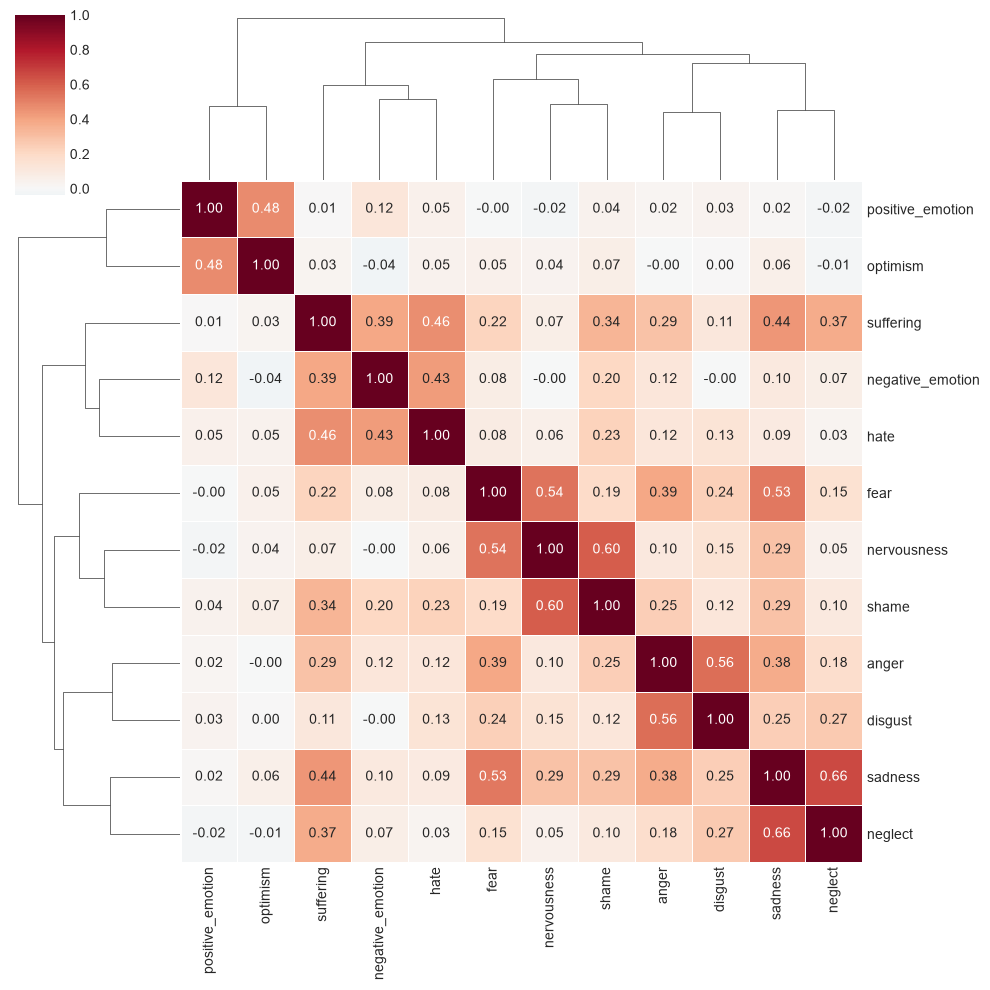

In [44]:
corr = emociones.corr()

plt.figure(figsize=(14,9))
sns.clustermap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5
)

plt.show()

El clustermap parece sugerir agrupaciones entre:
- Positive_emotion y optimism
- Nervousness y Shame
- Negative_emotion y Hate
- Sadness y Neglect
- Anger y Disgust

Para validar, se aplica Análisis Factorial Exploratorio que permita definir constructos que posteriormente se validarán con Análisis Factorial Confirmatorio

##### Análisis Factorial Exploratorio

Se obtienen los eigenvalores para estimar mediante diversos métodos el mejor número de factores

In [45]:
pca = PCA()
pca.fit(StandardScaler().fit_transform(emociones))
eigenvalues = pca.explained_variance_
eigen_df = pd.DataFrame({
    "Eigenvalue": eigenvalues
})

eigen_df

,Eigenvalue
0,3.252797
1,1.624700
2,1.478733
3,1.368806
4,1.127669
5,0.771328
6,0.645203
7,0.582194
8,0.445837
9,0.333620


###### **Criterio de Kaiser**

Consiste en conservar únicamente aquellos factores cuyos valores propios son mayores que 1. Esta regla heurística se basa en que, al trabajar con variables estandarizadas, cada variable original aporta una unidad de varianza al sistema. Por tanto, un factor solo se considera relevante si explica al menos tanta varianza como una variable individual. En consecuencia, los factores con valores propios superiores a la unidad se retienen para el análisis, mientras que aquellos con valores inferiores a 1 se descartan por representar una cantidad de información menor a la aportada por una variable original.

In [46]:
sum(eigenvalues > 1)

np.int64(5)

El criterio define 5 factores

###### **Criterio del codo**

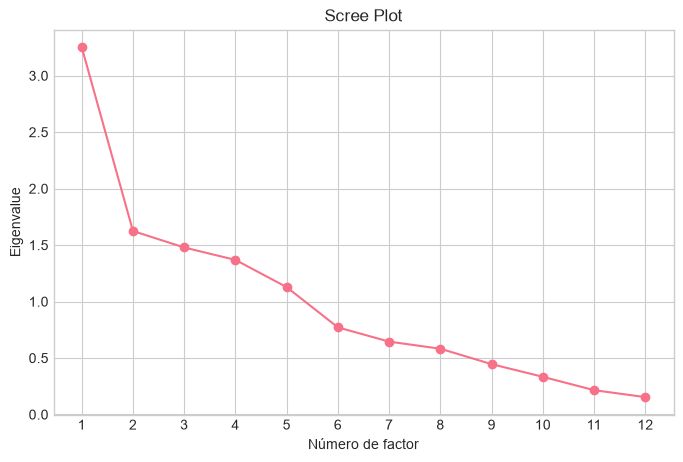

In [47]:
plt.figure(figsize=(8,5))
plt.plot(
    range(1, len(eigenvalues)+1, 1),
    eigenvalues,
    marker='o'
)

plt.xticks(list(range(1, len(eigenvalues)+1, 1)))

plt.xlabel("Número de factor")
plt.ylabel("Eigenvalue")
plt.title("Scree Plot")
plt.grid(True)
plt.show()

Se identifica que la curva se comienza a aplanar a partir del sexto factor. El método sugiere mantener entre 5 y 6 factores

###### **Análisis paralelo (Horn)**

El análisis de Horn compara los eigenvalores obtenidos con los eigenvalores esperados de muestras aleatorias con las dimensiones del problemas, y solo mantiene aquellas variables que explican más que el ruido aleatorio.

In [49]:
n_iter = 100
random_eigen = np.zeros((n_iter, emociones.shape[1]))

for i in range(n_iter):

    random_data = np.random.normal(
        size=(emociones.shape[0], emociones.shape[1])
    )

    pca_random = PCA()
    pca_random.fit(random_data)

    random_eigen[i, :] = pca_random.explained_variance_

mean_random_eigen = random_eigen.mean(axis=0)
n_factors_parallel = np.sum(eigenvalues > mean_random_eigen)

print(
    f"Factores sugeridos por Análisis Paralelo: "
    f"{n_factors_parallel}"
)

Factores sugeridos por Análisis Paralelo: 5


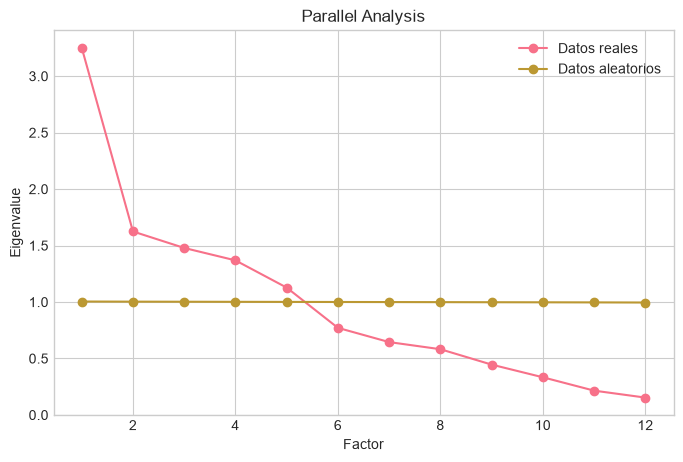

In [50]:
plt.figure(figsize=(8,5))

plt.plot(
    range(1, emociones.shape[1]+1),
    eigenvalues, 
    marker='o', 
    label='Datos reales')

plt.plot(
    range(1, emociones.shape[1]+1),
    mean_random_eigen,
    marker='o',
    label='Datos aleatorios'
)

plt.xlabel("Factor")
plt.ylabel("Eigenvalue")
plt.title("Parallel Analysis")
plt.legend()
plt.grid(True)

plt.show()

###### **Selección del mejor factor**

Los 3 métodos plantearon 5 factores como la mejor solución. Se interpretan:

In [19]:
fa = FactorAnalysis(
        n_components=5, rotation = "varimax", max_iter = 500)

fa.fit(StandardScaler().fit_transform(emociones))

loadings = pd.DataFrame(
    fa.components_.T,
    index=emociones.columns,
    columns=[
        f"Factor_{i+1}"
        for i in range(5)
    ]
)

loadings

,Factor_1,Factor_2,Factor_3,Factor_4,Factor_5
negative_emotion,-0.000306,0.062146,-0.035505,0.101213,0.572445
sadness,0.187126,0.196488,-0.948115,0.016094,0.092195
suffering,0.033146,0.170850,-0.358571,-0.014146,0.680880
fear,0.490976,0.297940,-0.396592,0.000032,-0.019535
nervousness,0.990821,0.026498,-0.107918,-0.008570,-0.012906
anger,0.059126,0.970811,-0.174272,0.003872,0.092601
shame,0.595394,0.162814,-0.123185,0.039420,0.344291
disgust,0.118637,0.544353,-0.128996,0.028505,0.001449
hate,0.063631,0.054284,-0.010063,0.036713,0.653221
neglect,-0.019439,0.050886,-0.677798,-0.022885,0.108543


- **Factor 1:** (Ansiedad, miedo y verguenza) Parece agrupar en general la ansiedad (Fear, Nervousness, Shame)
- **Factor 2:** (Hostilidad) Agrupa emociones reactivas como la ira y el disgusto (Anger y disgust)
- **Factor 3:** (Vulnerabilidad depresiva) Agrupa emociones de tristeza y sensación de abandono (Sadness y neglect)
- **Factor 4:** (Afectos positivos) Agrupa emociones positivas y de optimismo (Positive_emotion y optimism)
- **Factor 5:** (Malestar general) Agrupa negatividad, odio y otras categorías relacionadas (Negative_emotion, hate y suffering)

Teniendo en cuenta los factores, se transforman, se agrupan y se añaden al dataset para que sean parte de los atributos del grafo

In [ ]:
scores = fa.transform(StandardScaler().fit_transform(emociones))
scores_df = pd.DataFrame(scores, columns = ["Anxiety", "Hostility", "Sadness", "Positive", "Distress"])
df = pd.concat([df, scores_df], axis=1)